# C7 Fibroblast — identity & cross-species location (cleaned)

**What this notebook does, top to bottom**
1. Load human spatial object + Ulrich (PNAS 2024) atlas centroids
2. Compute shared objects **once** (`panel`, `Xlin`, `Ac`, `Ac_n`, `ref`, `stro`, `fib`)
3. Simple C7-marker readout — **spatial + UMAP** (human)
4. kNN-smoothed cosine mapping of every cell to all 39 atlas subtypes → `sim`
5. Cluster → subtype mapping (single `map_clusters`) + sink test
6. Validation battery (bleed, calibration, null, complement)
7. SAMap cross-species arm — project the C7 score onto mouse Slide-seq

---
### ⚠️ Changes made in cleanup — please verify
- **`mouse = human.copy()` removed.** In the original, cell 1 loaded the `XMens_Only` object into `human`, then `mouse = human.copy()`, then cell 3 overwrote `human` with `Human_Only`. So `mouse` actually held the *XMens* object, **not mouse**, and it was **never used downstream** (the mouse analysis all comes through the SAMap object). If you did need that object, re-add it with a real name (see the commented cell in §1).
- **Two different centering conventions were in use, almost certainly by accident** (a consequence of `map_clusters` being redefined mid-notebook): the **resolution sweep used `centering="fixed"`** while the **main mapping used `centering="symmetric"`**. I preserved *exact current behavior* so your outputs still match, but you should pick one deliberately — `symmetric` (both sides centered across subtypes/clusters) is the more internally-consistent cosine and is probably what you want for both.
- **Deduped:** `score_genes` (×3 → 1, kept the temp-AnnData version, which bins control genes on the actual log1p values), `map_clusters` (×3 → 1, parameterized on `centering`), atlas xlsx parse (×3 → 1, kept the version with the CP10K sanity check). Removed dead cells (`print('test')`, the bare `sc.pl.matrixplot` reference, and the redundant inline mapping that duplicated `map_clusters`).
- **I could not execute this** (no data / GPU / xlsx on my side) — this is a *structural* reorg. **Run top-to-bottom once and confirm outputs match** what you had; the reordering is the only thing that could bite.

In [1]:
!pwd

/n/lab_storage/eddy_lab/users/nhilgert/xmens_final/hammoud


## 0. Imports

In [2]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from sklearn.preprocessing import normalize

# GPU helpers (only needed for the kNN-cosine cell in §4)
import sys
sys.path.insert(0, '/n/lab_storage/eddy_lab/users/nhilgert/packages/gpu_utils')
from gpu_utils import *
import torch

gpu_utils: rapids-singlecell loaded. GPU acceleration enabled


In [5]:
!ls /n/netscratch/eddy_lab/Everyone/nhilgert/

20251008_Cevrim_Human_All_Cells.h5ad
20251008_Cevrim_Human_Only_Fib_Dec_Cells.h5ad
20251008_Cevrim_XMens_All_Cells.h5ad
20251008_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad
2026_08_05_Cevrim_Human_All_Cells_bak.h5ad
2026_08_05_Cevrim_Human_Only_Fib_Dec_Cells_bak.h5ad
2026_08_05_Cevrim_SAMap_Menstrual.h5ad
2026_08_05_Cevrim_SAMap_Secretory.h5ad
2026_08_05_Cevrim_XMens_All_Cells_bak.h5ad
2026_08_05_Cevrim_XMens_Only_Fib_Dec_Cells_bak.h5ad
2026_08_21_Cevrim_Human_All_Cells.h5ad
2026_08_21_Cevrim_Human_Only_Fib_Dec_Cells.h5ad
2026_08_21_Cevrim_XMens_All_Cells.h5ad
2026_08_21_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad
allcells.h5ad
endometriumAtlasV2_cells_with_counts.h5ad
endometriumAtlasV2_nuclei_counts.h5ad
stro7_margin.csv


## 1. Load data

In [6]:
human = sc.read_h5ad(
    "/n/netscratch/eddy_lab/Everyone/nhilgert/"
    "2026_08_21_Cevrim_Human_Only_Fib_Dec_Cells.h5ad")

# spatial coords as an obsm basis (used by several spatial plots below)
human.obsm["X_spatial_dbscan"] = human.obs[["x_um_dbscan", "y_um_dbscan"]].to_numpy(float)

# --- OPTIONAL: the XMens object (was loaded as `mouse` in the original, but never used).
#     Uncomment with a clear name only if you actually need it here.
# xmens = sc.read_h5ad(
#     "/n/lab_storage/eddy_lab/users/nhilgert/decidualization/revisions/adatas/"
#     "submission/20251008_Cevrim_XMens_Only_Fib_Dec_Cells.h5ad")

## 2. Atlas centroid table (Ulrich 2024, Dataset S5) — parsed once, with CP10K check

In [7]:
PATH  = "pnas.2404775121.sd05.xlsx"          # needs openpyxl
SHEET = "5B Subtype centroids"

xl = pd.ExcelFile(PATH)
df = xl.parse(SHEET, header=2, index_col=0)

# clean: embedded newlines in headers, junk index rows, non-numeric cells
df.columns = (pd.Index(df.columns).astype(str)
                .str.replace(r"\s+", " ", regex=True).str.strip())
df.index   = df.index.astype(str).str.strip()
df = df[~df.index.isin(["nan", ""])]
df = df.apply(pd.to_numeric, errors="coerce")
print(f"{df.shape[0]:,} genes x {df.shape[1]} subtypes")

# sanity: centroids should be log1p(CP10K) -> expm1 sums to ~1e4 per column
sums = np.expm1(df).sum(axis=0)
print(f"median sum expm1(centroid): {sums.median():,.0f}  (ratio to 1e4: {sums.median()/1e4:.3f})")

# subtype column groups reused throughout
stro = [c for c in df.columns if c.startswith("Stro-")]
fib  = ["Stro-5_RUNX3+ Fibroblast", "Stro-7_C7 Fibroblast", "Stro-8_dS1",
        "Stro-9_dS2", "Stro-10_dS3", "Stro-11_Stromal progenitor"]

43,090 genes x 39 subtypes
median sum expm1(centroid): 10,000  (ratio to 1e4: 1.000)


## 3. Shared objects (computed once): `panel`, `Xlin`, `Ac`, `Ac_n`, `ref`

In [8]:
human.layers['log1p'] = human.X.copy()

In [9]:
# discriminative panel: genes with highest variance across the 39 atlas subtypes
common = human.var_names.intersection(df.index)
panel  = df.loc[common].var(axis=1).nlargest(3000).index

# linear expression on the panel (expm1 preserves zeros -> sparsity survives)
Xlin = sp.csr_matrix(human[:, panel].layers["log1p"], dtype=np.float32).copy()
Xlin.data = np.expm1(Xlin.data)

# atlas side over stromal subtypes: center per gene across subtypes, then L2-normalize
Ac   = df.loc[panel, stro].sub(df.loc[panel, stro].mean(axis=1), axis=0)
Ac_n = normalize(Ac.T, axis=1)                    # subtypes x genes

# fixed all-cells reference (used by the 'fixed' centering option in map_clusters)
ref  = np.log1p(np.asarray(Xlin.mean(axis=0)).ravel())

## 4. Simple C7-marker readout — **spatial + UMAP** (human)

The literal "where are the C7 fibroblast markers" question. `score_genes` is run via a temp
AnnData so control-gene binning uses the log1p values (not `.X`).

In [10]:
fibro_genes = [
    "APOD", "C7", "DCN", "CCDC80", "ADH1B", "GSN", "SERPINF1", "OGN",
    "SCN7A", "DPT", "RARRES2", "CTSK", "ASPN", "LUM", "FBLN1", "SRPX",
    "GPNMB", "TIMP1", "MATN2", "CST3", "SPOCK1", "PLXDC2", "OMD",
    "ITM2A", "PID1", "PODN", "HTRA3",
]
present = [g for g in fibro_genes if g in human.var_names]
missing = sorted(set(fibro_genes) - set(present))
print(f"{len(present)}/{len(fibro_genes)} present | missing: {missing}")

tmp = ad.AnnData(X=human.layers["log1p"], obs=human.obs[[]].copy(), var=human.var[[]].copy())
sc.tl.score_genes(tmp, present, score_name="fibro_score", use_raw=False, random_state=0)
human.obs["fibro_score"] = tmp.obs["fibro_score"].values

27/27 present | missing: []


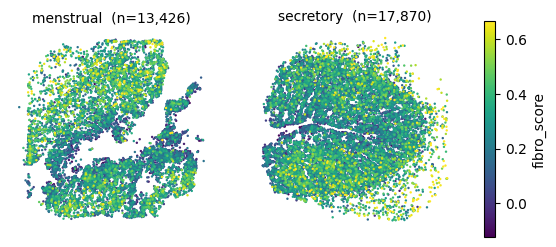

In [11]:
# --- SPATIAL: fibro_score per timepoint, one shared color scale ---
tp_col = "timepoint"
tps = (list(human.obs[tp_col].cat.categories) if str(human.obs[tp_col].dtype) == "category"
       else sorted(human.obs[tp_col].unique()))
vmin, vmax = np.nanpercentile(human.obs["fibro_score"].to_numpy(float), [1, 99])

fig, axes = plt.subplots(1, len(tps), figsize=(3.6 * len(tps), 4.0))
axes = np.atleast_1d(axes)
for ax, tp in zip(axes, tps):
    sub = human.obs.loc[human.obs[tp_col] == tp, ["x_um_dbscan", "y_um_dbscan", "fibro_score"]]
    x, y, s = (sub[c].to_numpy(float) for c in sub.columns)
    m = np.isfinite(x) & np.isfinite(y); x, y, s = x[m], y[m], s[m]
    o = np.argsort(s)                                  # high scores on top
    pts = ax.scatter(x[o], y[o], c=s[o], s=3, cmap="viridis",
                     vmin=vmin, vmax=vmax, linewidths=0, rasterized=True)
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_axis_off()
    ax.set_title(f"{tp}  (n={m.sum():,})", fontsize=10)
fig.colorbar(pts, ax=axes, shrink=0.7, label="fibro_score")

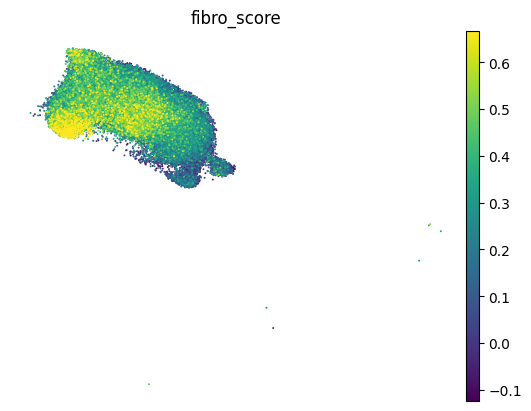

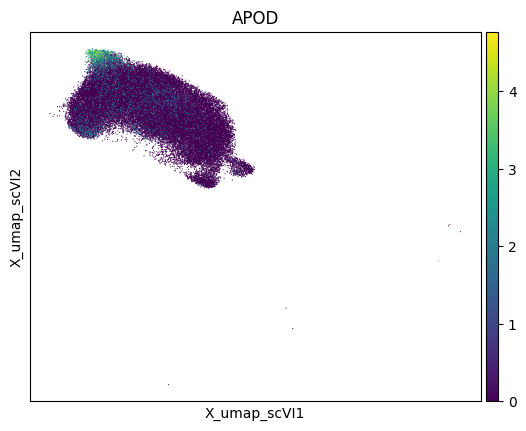

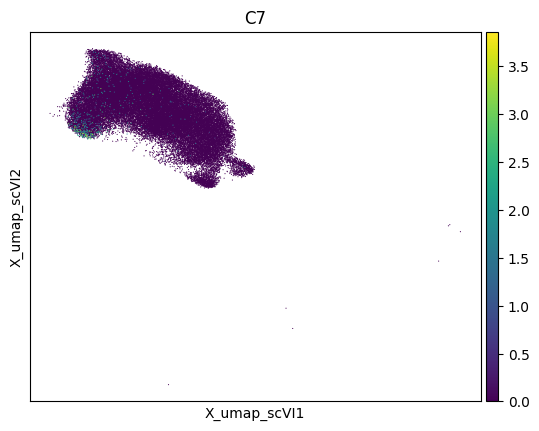

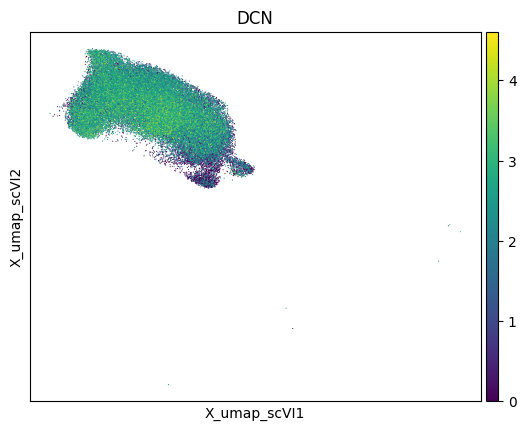

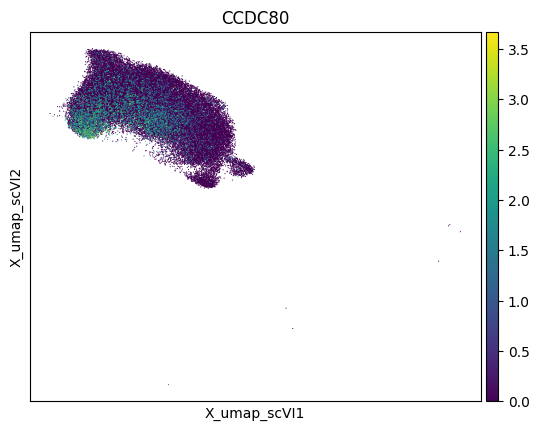

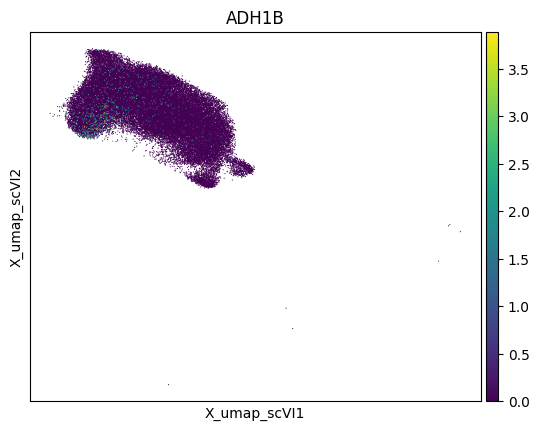

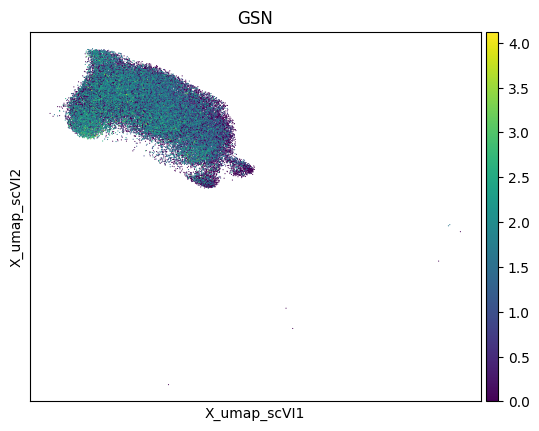

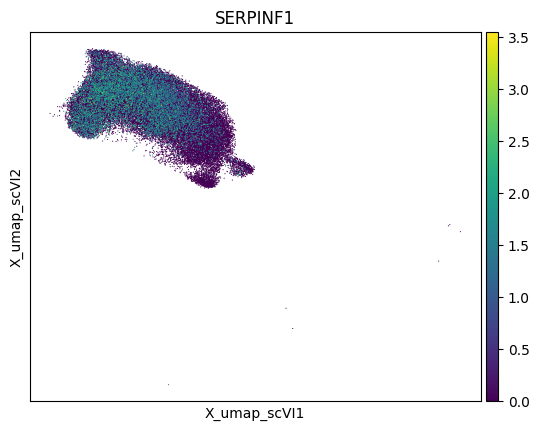

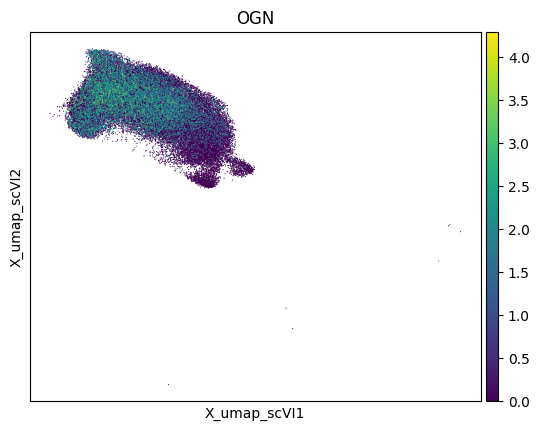

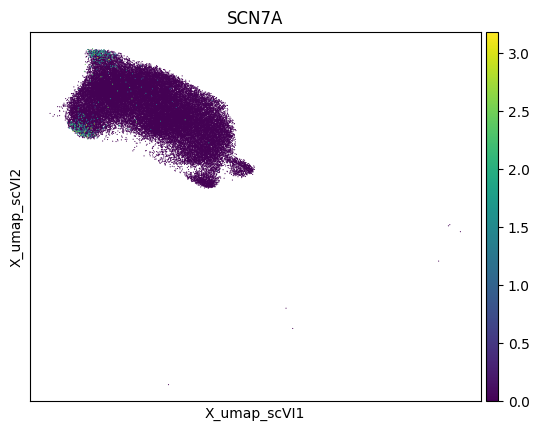

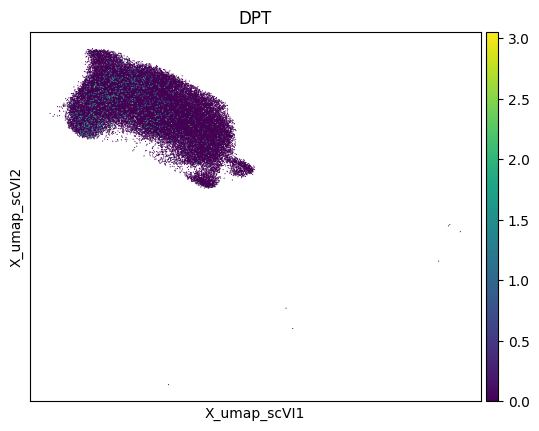

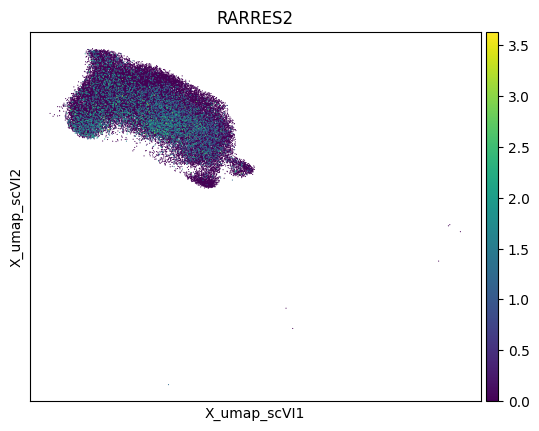

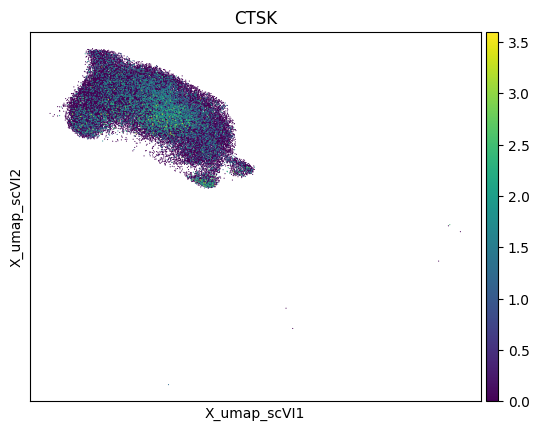

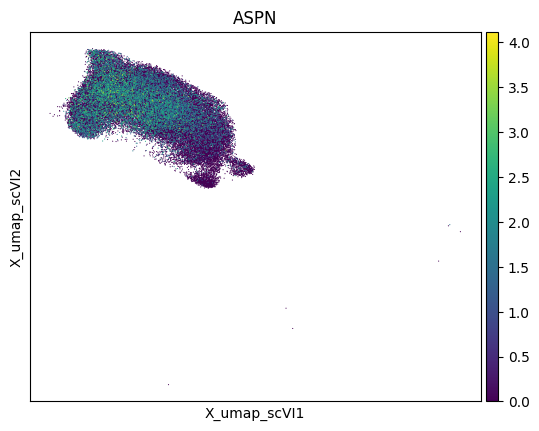

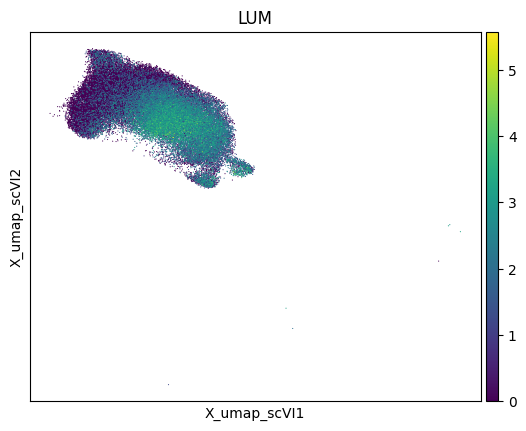

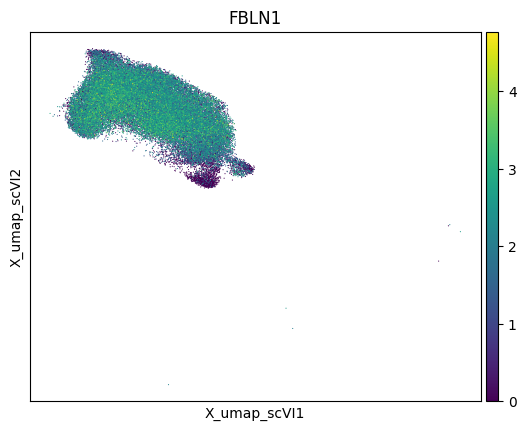

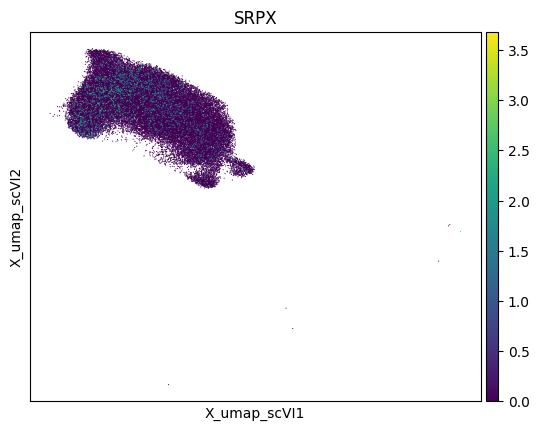

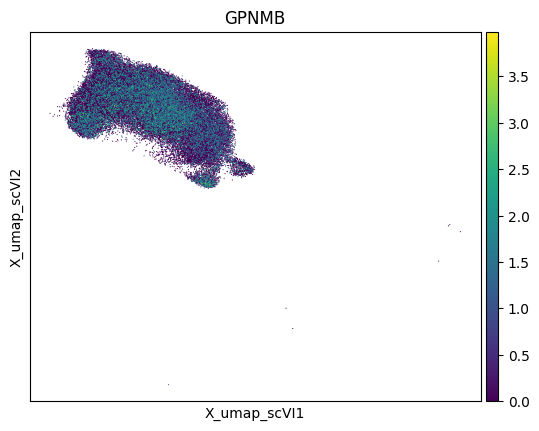

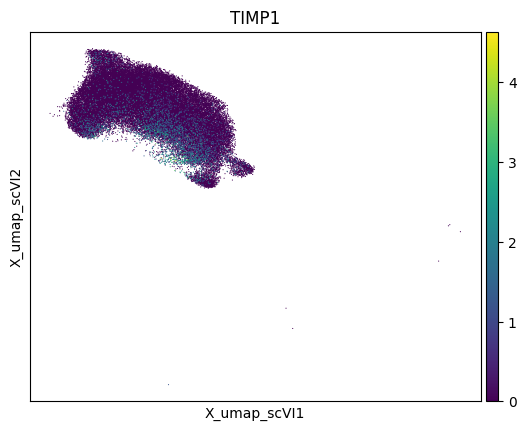

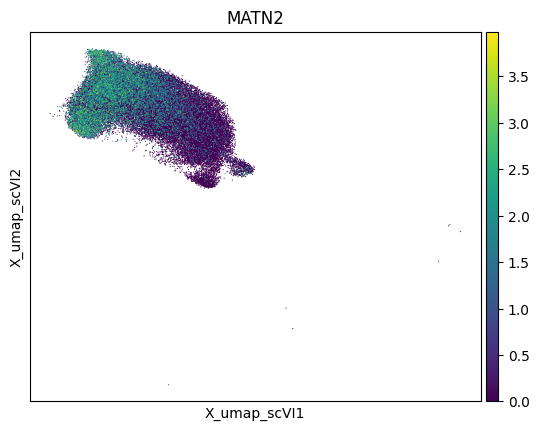

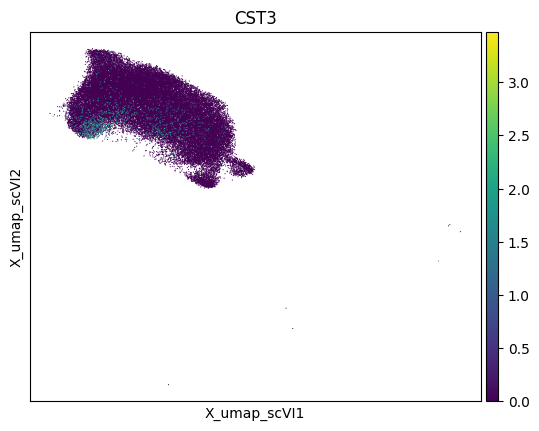

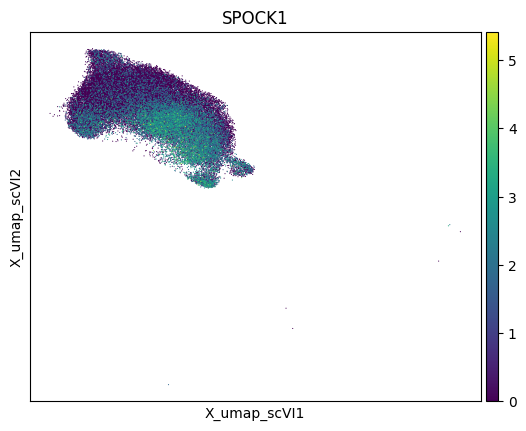

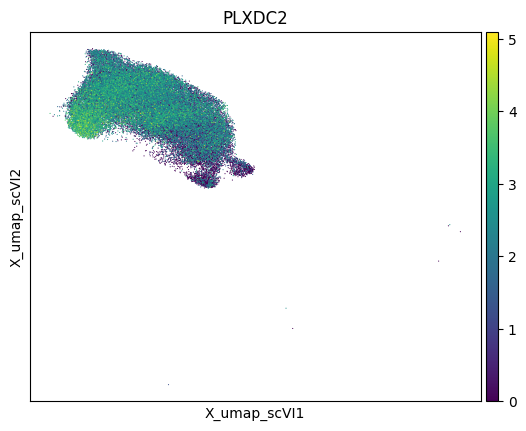

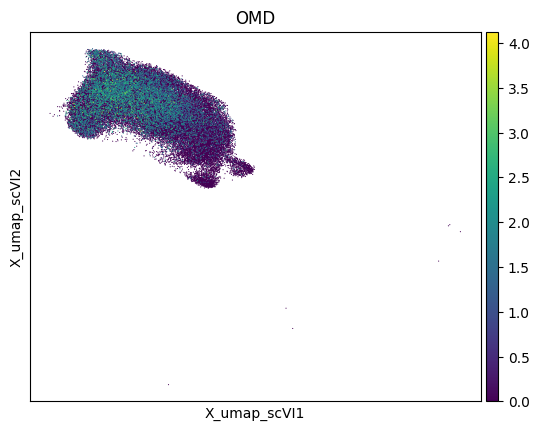

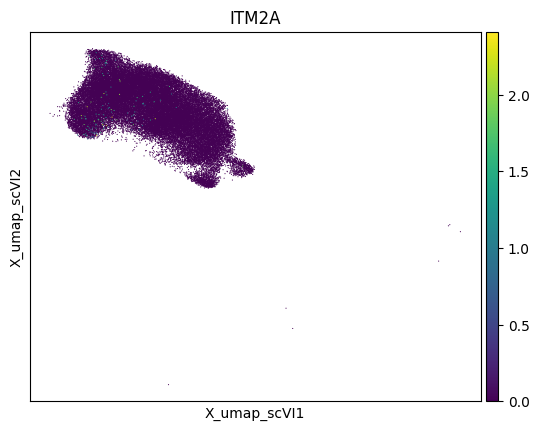

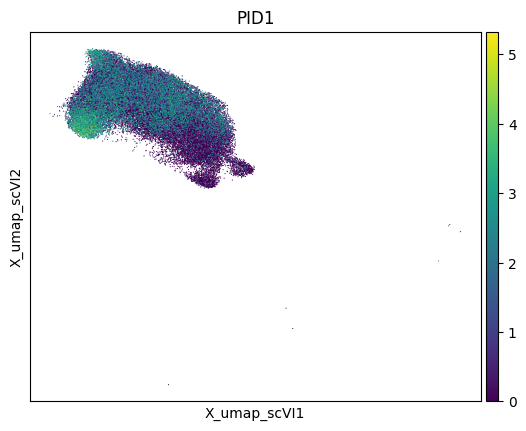

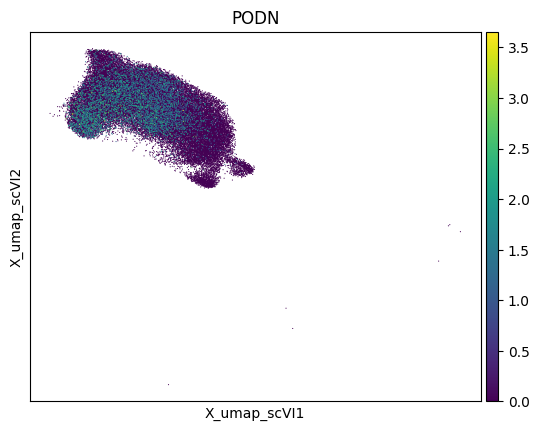

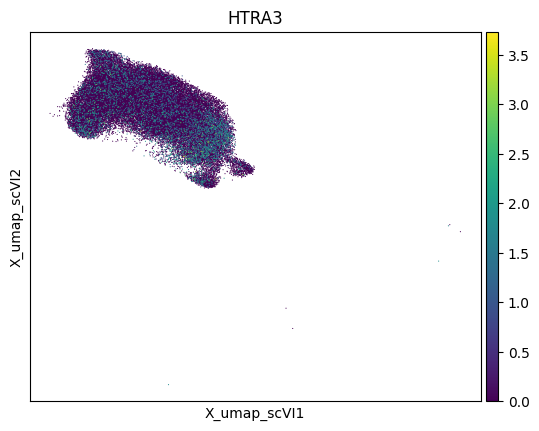

In [14]:
# --- UMAP: fibro_score, then per-gene ---
sc.pl.embedding(human, basis="X_umap_scVI", color="fibro_score",
                cmap="viridis", vmin="p1", vmax="p99", size=8, frameon=False)

# per-gene UMAPs (verbose: one panel per marker)
for gene in fibro_genes:
    if gene in human.var_names:
        sc.pl.embedding(human, basis="X_umap_scVI", color=gene, layer="log1p")

_Note: there is no mouse UMAP in these objects — the mouse readout is spatial (Slide-seq pucks) + dotplot, in §7._

## 5. Map every cell to all 39 atlas subtypes — kNN-smoothed cosine (GPU)

In [15]:
dev, K, BLOCK = "cuda", 30, 512

# 0. verify the layer is CP10K (expm1 row-sums ~1e4)
print(np.expm1(human.layers["log1p"][:500]).sum(axis=1).A.ravel()[:5])

# 1. atlas panel in log space, centered across subtypes
A  = df.loc[panel].to_numpy(np.float32)
A -= A.mean(axis=1, keepdims=True)
A_t, A_norm = torch.as_tensor(A, device=dev), torch.as_tensor(A, device=dev).norm(dim=0)

# 2. unweighted kNN operator (matches AverageExpression semantics)
sc.pp.neighbors(human, use_rep="X_scVI", n_neighbors=K, key_added=f"nbr{K}")
S = (human.obsp[f"nbr{K}_distances"] > 0).astype(np.float32) \
    + sp.eye(human.n_obs, dtype=np.float32, format="csr")
S = normalize(S, norm="l1", axis=1).tocsr()
S_t = torch.sparse_csr_tensor(torch.as_tensor(S.indptr.astype(np.int64)),
                              torch.as_tensor(S.indices.astype(np.int64)),
                              torch.as_tensor(S.data), size=S.shape).to(dev)

# 3. linear space (expm1 preserves zeros)
Xpan = sp.csr_matrix(human[:, panel].layers["log1p"], dtype=np.float32).copy()
Xpan.data = np.expm1(Xpan.data)

# 4. streaming: average LINEAR over neighbours, then log, then center, then cosine
dot = torch.zeros(human.n_obs, A.shape[1], device=dev)
msq = torch.zeros(human.n_obs, device=dev)
for lo in range(0, len(panel), BLOCK):
    hi  = min(lo + BLOCK, len(panel))
    blk = torch.as_tensor(Xpan[:, lo:hi].toarray(), device=dev)
    Mb  = torch.log1p(torch.sparse.mm(S_t, blk))
    Mb -= Mb.mean(0, keepdim=True)
    dot += Mb @ A_t[lo:hi]
    msq += (Mb * Mb).sum(1)
    del blk, Mb

sim = pd.DataFrame((dot / (msq.sqrt().unsqueeze(1) * A_norm)).cpu().numpy(),
                   index=human.obs_names, columns=df.columns)
assert sim.index.equals(human.obs_names) and len(sim) == human.n_obs

[10000.     9999.999  9999.999 10000.    10000.   ]


/tmp/ipykernel_3993513/3627131358.py:16: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:760.)
  S_t = torch.sparse_csr_tensor(torch.as_tensor(S.indptr.astype(np.int64)),
/tmp/ipykernel_3993513/3627131358.py:16: UserWarning: Sparse CSR tensor support is in beta state. If you miss a functionality in the sparse tensor support, please submit a feature request to https://github.com/pytorch/pytorch/issues. (Triggered internally at /pytorch/aten/src/ATen/SparseCsrTensorImpl.cpp:49.)
  S_t = torch.sparse_csr_tensor(torch.as_tensor(S.indptr.astype(np.int64)),


## 6. Cluster → subtype mapping

Single `map_clusters`, parameterized on `centering`:
- `"symmetric"` (default): center genes across clusters on your side, matching the atlas centering — the internally-consistent cosine.
- `"fixed"`: center your side against the fixed all-cells `ref`.

⚠️ The original used **`fixed` for the sweep** and **`symmetric` for the main result** (accident of redefinition order). Preserved below — unify if that wasn't intended.

In [16]:
def map_clusters(lab, centering="symmetric"):
    lab    = pd.Series(np.asarray(lab), index=human.obs_names).astype(str)
    groups = sorted(lab.unique(), key=lambda g: int(g) if g.isdigit() else g)
    C = pd.DataFrame(
        {g: np.log1p(np.asarray(Xlin[(lab == g).to_numpy()].mean(axis=0)).ravel())
         for g in groups}, index=panel)
    Cc = C.sub(ref, axis=0) if centering == "fixed" else C.sub(C.mean(axis=1), axis=0)
    M = pd.DataFrame(normalize(Cc.T, axis=1) @ Ac_n.T, index=C.columns, columns=Ac.columns)
    tbl = pd.DataFrame({
        "best":   M.idxmax(1),
        "margin": M.max(1) - M.apply(lambda r: r.nlargest(2).iloc[1], axis=1),
        "n":      lab.value_counts().reindex(M.index).astype(int),
    })
    return M, tbl

print(Ac.pow(2).sum().pow(0.5).sort_values().round(2))   # centered norm per atlas column

Stro-9_dS2                                     8.57
Stro-3_PV STEAP4                              10.05
Stro-6_uSMC                                   10.81
Stro-4_Tissue resident vascular progenitor    11.42
Stro-8_dS1                                    12.07
Stro-10_dS3                                   12.87
Stro-7_C7 Fibroblast                          13.09
Stro-5_RUNX3+ Fibroblast                      13.57
Stro-2_PV MYH11 FOXC1lo CTGFhi                16.08
Stro-11_Stromal progenitor                    16.72
Stro-1_PV MYH11 FOXC1hi CTGFlo                17.84
dtype: float64


In [17]:
# resolution sweep  (ORIGINAL BEHAVIOR: centering='fixed')
rows = []
for res in [2.0]:
    key = f"leiden_{res}"
    sc.tl.leiden(human, resolution=res, neighbors_key="nbr30", key_added=key,
                 flavor="igraph", n_iterations=2)
    lab = human.obs[key].astype(str)
    M_s, tbl_s = map_clusters(lab, centering="fixed")
    rows.append({"res": res, "n_clusters": lab.nunique(),
                 "distinct_matches": tbl_s.best.nunique(),
                 "median_margin": round(tbl_s.margin.median(), 3),
                 "smallest": int(tbl_s.n.min())})
print(pd.DataFrame(rows))

   res  n_clusters  distinct_matches  median_margin  smallest
0  2.0          21                 6           0.04         4


In [18]:
# main mapping  (ORIGINAL BEHAVIOR: centering='symmetric')  -> M, tbl used downstream
#M, tbl = map_clusters(human.obs["leiden_2.0"], centering="symmetric")

#print(tbl.best.value_counts())                                   # the sink test
#print(tbl[tbl.n >= 100].sort_values("margin", ascending=False).round(3))

# per-cell Stro-7 margin + best-subtype label, for the embeddings below
human.obs["stro7_margin"] = (sim["Stro-7_C7 Fibroblast"]
                             - sim[stro].drop(columns="Stro-7_C7 Fibroblast").max(1)).to_numpy()
human.obs["best_stro"]    = sim[stro].idxmax(1).to_numpy()

## 7. Validation battery

... storing 'best_stro' as categorical


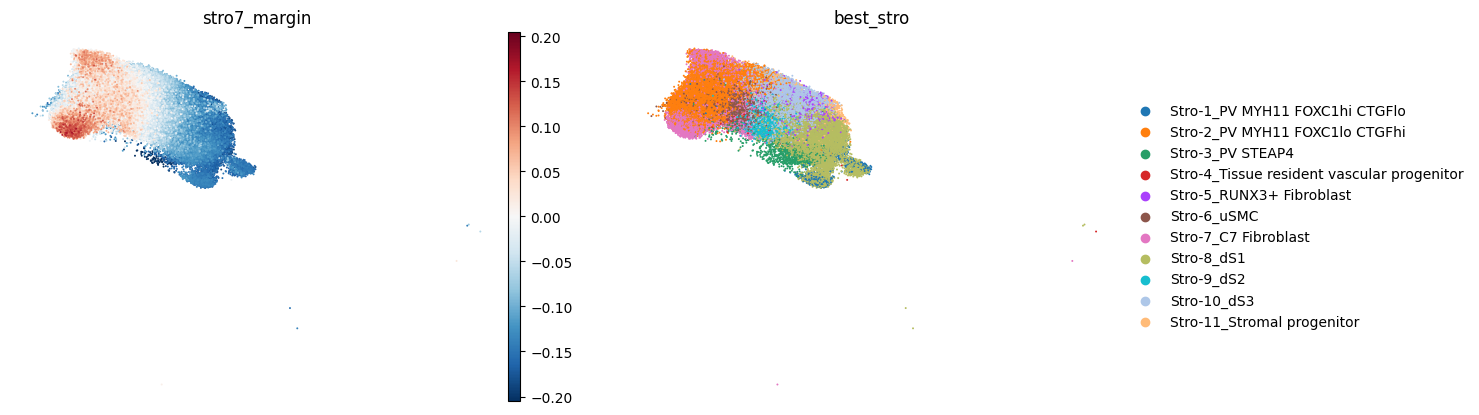

In [19]:
# Stro-7 margin, best-subtype, and clusters on the UMAP
lim = np.nanpercentile(np.abs(human.obs["stro7_margin"]), 99)
sc.pl.embedding(human, basis="X_umap_scVI",
                color=["stro7_margin", "best_stro"],
                cmap="RdBu_r", vmin=-lim, vcenter=0, vmax=lim,
                size=8, frameon=False, ncols=3)

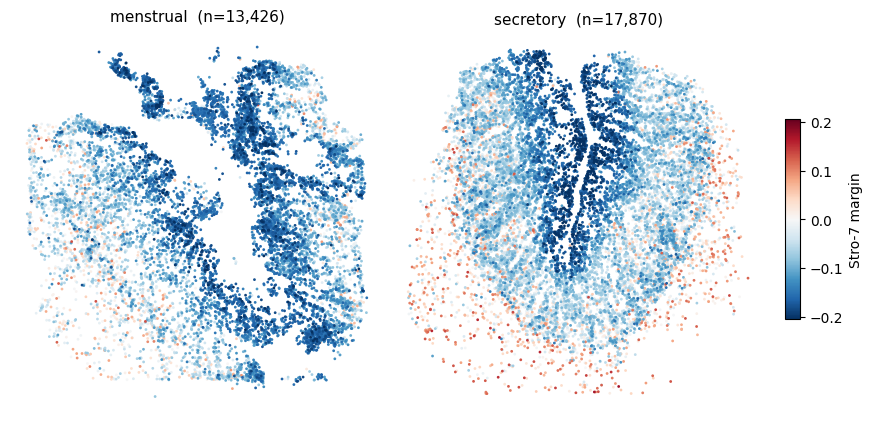

In [20]:
import numpy as np, matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

TIMEPOINTS = ["menstrual", "secretory"]
ROTATE_DEG = {"menstrual": 270, "secretory": 90}      # <-- per-timepoint angle (CCW in data space)

assert "stro7_margin" in human.obs, "run the mapping section first (defines stro7_margin)"

def rotate(x, y, deg, cx=None, cy=None):
    """Rotate points by `deg` about (cx, cy); defaults to their centroid."""
    cx = x.mean() if cx is None else cx
    cy = y.mean() if cy is None else cy
    t  = np.deg2rad(deg)
    xr = cx + (x - cx) * np.cos(t) - (y - cy) * np.sin(t)
    yr = cy + (x - cx) * np.sin(t) + (y - cy) * np.cos(t)
    return xr, yr

tp_col = "timepoint"
sel = human.obs[tp_col].isin(TIMEPOINTS)
lim = np.nanpercentile(np.abs(human.obs.loc[sel, "stro7_margin"].to_numpy(float)), 99)
norm = TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, tp in zip(axes, TIMEPOINTS):
    d = human.obs.loc[human.obs[tp_col] == tp,
                      ["x_um_dbscan", "y_um_dbscan", "stro7_margin"]]
    x, y, s = (d[c].to_numpy(float) for c in d.columns)
    m = np.isfinite(x) & np.isfinite(y)
    x, y, s = x[m], y[m], s[m]

    x, y = rotate(x, y, ROTATE_DEG.get(tp, 0))       # <-- per-timepoint; default 0 if unlisted

    o = np.argsort(np.abs(s))                          # strongest calls on top
    pts = ax.scatter(x[o], y[o], c=s[o], cmap="RdBu_r", norm=norm,
                     s=4, linewidths=0, rasterized=True)
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_axis_off()
    ax.set_title(f"{tp}  (n={m.sum():,})", fontsize=11)

fig.subplots_adjust(right=0.88, wspace=0.02)
cax = fig.add_axes([0.90, 0.30, 0.015, 0.40])
fig.colorbar(pts, cax=cax, label="Stro-7 margin")

In [21]:
import pandas as pd
SCRATCH = "/n/netscratch/eddy_lab/Everyone/nhilgert"

# export stro7_margin keyed by obs_names (the join key)
out = human.obs[["stro7_margin"]].copy()
out.index.name = "obs_name"
out.to_csv(f"{SCRATCH}/stro7_margin.csv")
print(f"wrote {out.shape[0]} rows -> {SCRATCH}/stro7_margin.csv")
print(f"non-NaN stro7_margin: {out['stro7_margin'].notna().sum()}")

wrote 47533 rows -> /n/netscratch/eddy_lab/Everyone/nhilgert/stro7_margin.csv
non-NaN stro7_margin: 47533


In [22]:
import anndata as ad, pandas as pd, numpy as np
SCRATCH = "/n/netscratch/eddy_lab/Everyone/nhilgert"

# load the human object we're working with here
a = ad.read_h5ad(f"{SCRATCH}/2026_08_21_Cevrim_Human_Only_Fib_Dec_Cells.h5ad")

# read the exported score, align by obs_names
s = pd.read_csv(f"{SCRATCH}/stro7_margin.csv", index_col="obs_name")
aligned = s["stro7_margin"].reindex(a.obs_names)
matched = int(aligned.notna().sum())
print(f"matched {matched}/{a.n_obs} cells by obs_name ({100*matched/a.n_obs:.1f}%)")
if matched == 0:
    raise ValueError("0 matches — obs_names differ between the two objects; need a different key")
if matched < a.n_obs:
    print(f"  {a.n_obs - matched} cells have no stro7_margin -> NaN (expected if the other "
          f"object was a subset, or scores were only computed for some cells)")

a.obs["stro7_margin"] = aligned.values

# save back to scratch (temp + move, to avoid the open-file truncation error)
import shutil
tmp = f"{SCRATCH}/_tmp_human_allcells.h5ad"
a.write_h5ad(tmp); del a
shutil.move(tmp, f"{SCRATCH}/2026_08_21_Cevrim_Human_All_Cells.h5ad")
print("saved human object with stro7_margin added")

matched 47533/47533 cells by obs_name (100.0%)
saved human object with stro7_margin added


In [23]:
# Two orthogonal marker-agreement checks: atlas markers -> clusters, and my markers -> atlas
def zrow(X):
    return X.sub(X.mean(1), axis=0).div(X.std(1).replace(0, np.nan), axis=0)

Xa = sp.csr_matrix(human[:, common].layers["log1p"], dtype=np.float32).copy()
Xa.data = np.expm1(Xa.data)

KEY    = "leiden_2.0"
lab    = human.obs[KEY].astype(str)
groups = sorted(lab.unique(), key=int)
C_all  = pd.DataFrame({g: np.log1p(np.asarray(Xa[(lab == g).to_numpy()].mean(axis=0)).ravel())
                       for g in groups}, index=common)
A_all  = df.loc[common, stro]
Cz, Az = zrow(C_all), zrow(A_all)

# A: atlas markers -> your clusters
mk_atlas = {}
for c in A_all.columns:
    d = (A_all[c] - A_all.drop(columns=c).max(1))[A_all[c] > 0.5]
    mk_atlas[c] = d.nlargest(50).index
scoreA = pd.DataFrame({c: Cz.loc[mk].mean() for c, mk in mk_atlas.items()})

# B: your markers -> atlas centroids
sc.tl.rank_genes_groups(human, KEY, method="wilcoxon", layer="log1p", use_raw=False, pts=True)
scoreB = pd.DataFrame({
    g: Az.loc[[x for x in sc.get.rank_genes_groups_df(human, g)
                 .query("logfoldchanges > 1 & pct_nz_group > 0.25")
                 .head(50).names if x in Az.index]].mean()
    for g in groups}).T

print(pd.DataFrame({"centroid": M.idxmax(1), "atlas_mk": scoreA.idxmax(1),
                    "my_mk": scoreB.idxmax(1), "n": lab.value_counts()}))

/n/lab_storage/eddy_lab/users/nhilgert/.uv/envs/rsc_uv/lib64/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:458: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "names"] = self.var_names[global_indices]
/n/lab_storage/eddy_lab/users/nhilgert/.uv/envs/rsc_uv/lib64/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:460: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "scores"] = scores[global_indices]
/n/lab_storage/eddy_lab/users/nhilgert/.uv/envs/rsc_uv/lib64/python

NameError: name 'M' is not defined

In [ ]:
# three-way agreement (centroid == atlas-marker == my-marker)
three = pd.DataFrame({
    "centroid": M.idxmax(1), "margin": tbl.margin.round(3),
    "atlas_mk": scoreA.idxmax(1), "my_mk": scoreB.idxmax(1), "n": tbl.n,
}).loc[tbl.n >= 100]
three["agree"] = (three.centroid == three.atlas_mk) & (three.centroid == three.my_mk)
print(three.sort_values(["agree", "margin"], ascending=False))

In [ ]:
# Is the PV/SMC signal real bleed, or just argmax with nowhere else to go?
sc.pl.dotplot(human, {"SMC": ["ACTA2", "DES", "MYH11", "TAGLN"],
                      "PV":  ["RGS5", "MCAM", "NOTCH3", "PDGFRB"],
                      "C7":  ["C7", "CFH", "CTSK"]},
              groupby="leiden_2.0", use_raw=False, layer="log1p")

# restrict atlas columns to what this lineage can contain, then re-map
Ac_fib   = df.loc[panel, fib].sub(df.loc[panel, fib].mean(axis=1), axis=0)
Ac_n_fib = normalize(Ac_fib.T, axis=1)
_Ac, _Ac_n = Ac, Ac_n
Ac, Ac_n  = Ac_fib, Ac_n_fib          # map_clusters reads the globals
M_fib, tbl_fib = map_clusters(human.obs["leiden_2.0"], centering="symmetric")
Ac, Ac_n  = _Ac, _Ac_n                 # restore
print(tbl_fib.sort_values("margin", ascending=False).round(3))

In [ ]:
# complement / matrix marker fraction-positive per cluster
genes = ["C7", "CFH", "CTSK", "C3", "C1S", "C1R", "CFD", "DCN", "LUM", "MGP"]
g_ok  = [g for g in genes if g in human.var_names]
pos   = pd.DataFrame((human[:, g_ok].layers["log1p"] > 0).toarray(),
                     index=human.obs_names, columns=g_ok)
fp = pos.groupby(human.obs["leiden_2.0"].values).mean()
print(fp.round(3))
print("\nobject-wide:", pos.mean().round(4).to_dict())
print("C7 in panel:", "C7" in panel)

In [ ]:
# Calibration: is C7 SPECIFICALLY high in the candidate cluster (11), or just riding the trend?
c11  = (human.obs["leiden_2.0"].astype(str) == "11").to_numpy()
Xl   = sp.csr_matrix(human[:, common].layers["log1p"], dtype=np.float32).copy()
Xl.data = np.expm1(Xl.data)
cen11 = pd.Series(np.log1p(np.asarray(Xl[c11].mean(axis=0)).ravel()), index=common)

s7  = df.loc[common, "Stro-7_C7 Fibroblast"]
mk  = (s7 - df.loc[common, fib].drop(columns="Stro-7_C7 Fibroblast").max(1)).nlargest(150).index

cal = pd.DataFrame({"atlas": s7[mk], "cl11": cen11[mk]})
fit = np.polyfit(cal.atlas, cal.cl11, 1)
cal["resid"] = cal.cl11 - np.polyval(fit, cal.atlas)
print(f"spearman: {cal.atlas.corr(cal.cl11, method='spearman'):.3f}")
print(cal.loc[["C7", "CFH", "CTSK"]].round(3))
print(f"C7 residual percentile: {(cal.resid < cal.loc['C7','resid']).mean():.2f}")

In [ ]:
# Which cluster's centroid best correlates with the Stro-7 centroid (detectable markers only)
Xb  = sp.csr_matrix(human[:, common].layers["log1p"])
det = pd.Series(np.asarray((Xb > 0).sum(axis=0)).ravel() / human.n_obs, index=common)
mk2 = [g for g in mk if s7[g] > 1.0 and det[g] > 0.05]
print(f"panel: {len(mk)} -> {len(mk2)}")

lab  = human.obs["leiden_2.0"].astype(str)
cens = {g: pd.Series(np.log1p(np.asarray(Xl[(lab == g).to_numpy()].mean(axis=0)).ravel()),
                     index=common)
        for g in sorted(lab.unique(), key=int)}
rank = pd.Series({g: s7[mk2].corr(c[mk2], method="spearman") for g, c in cens.items()})
print(rank.sort_values(ascending=False).round(3))

# centered version (vs other clusters / other subtypes)
Z  = pd.DataFrame({g: c[mk2] for g, c in cens.items()})
Zc = Z.sub(Z.mean(1), axis=0)
Af = df.loc[mk2, fib].sub(df.loc[mk2, fib].mean(1), axis=0)
rank2 = Zc.corrwith(Af["Stro-7_C7 Fibroblast"], method="spearman")
print(rank2.sort_values(ascending=False).round(3))

In [ ]:
# Null test: does the Stro-7 top-quantile overlap cluster 11 more than shuffled? + where C7+ cells sit
s   = sim["Stro-7_C7 Fibroblast"].to_numpy()
c11 = (human.obs["leiden_2.0"].astype(str) == "11").to_numpy()
jac = lambda a, b: (a & b).sum() / (a | b).sum()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(s[~c11], bins=80, density=True, alpha=.6, label="other")
ax[0].hist(s[c11],  bins=80, density=True, alpha=.6, label="cluster 11")
ax[0].set_xlabel("Stro-7 similarity"); ax[0].legend()

qs  = np.linspace(0.50, 0.995, 60)
rng = np.random.default_rng(0); sh = rng.permutation(s)
for col in ["Stro-7_C7 Fibroblast", "Stro-10_dS3", "Stro-8_dS1", "Stro-11_Stromal progenitor"]:
    v = sim[col].to_numpy()
    ax[1].plot(qs, [jac(v >= np.quantile(v, q), c11) for q in qs], label=col.split("_")[0])
ax[1].plot(qs, [jac(sh >= np.quantile(sh, q), c11) for q in qs], "k:", label="shuffled")
ax[1].set_xlabel("quantile"); ax[1].set_ylabel("Jaccard vs cl 11"); ax[1].legend(fontsize=8)

c7 = np.asarray((human[:, "C7"].layers["log1p"] > 0).todense()).ravel()
sel = s >= np.quantile(s, 0.91)          # ~9%, matched to cluster 11's size
print(pd.Series({"selected": c7[sel].mean(), "cluster11": c7[c11].mean(),
                 "both": c7[sel & c11].mean(), "neither": c7[~sel & ~c11].mean()}).round(4))

In [ ]:
# Define the C7 core (top Stro-7 score AND in cluster 11) and map it spatially per timepoint
s = sim["Stro-7_C7 Fibroblast"].to_numpy()
human.obs["c7_core"] = ((s >= np.quantile(s, 0.91)) &
                        (human.obs["leiden_2.0"].astype(str) == "11")).astype(int)
human.obs["c11"]     = (human.obs["leiden_2.0"].astype(str) == "11").astype(int)
human.obs["stro7"]   = s
human.obs["C7_pos"]  = np.asarray((human[:, "C7"].layers["log1p"] > 0).todense()).ravel().astype(int)

obs  = human.obs
tps  = (list(obs["timepoint"].cat.categories) if str(obs["timepoint"].dtype) == "category"
        else sorted(obs["timepoint"].unique()))
rows = [("Stro-7 score", "stro7", "RdBu_r"), ("cluster 11", "c11", "magma_r"),
        ("C7+ cells", "C7_pos", "magma_r"), ("C7 core", "c7_core", "magma_r")]

fig, axes = plt.subplots(len(rows), len(tps),
                         figsize=(3.2 * len(tps), 3.3 * len(rows)), squeeze=False)
for i, (label, col, cmap) in enumerate(rows):
    v = obs[col].to_numpy(float); lim = np.nanpercentile(np.abs(v), 99)
    for j, tp in enumerate(tps):
        m = (obs["timepoint"] == tp).to_numpy()
        x, y = obs["x_um_dbscan"].to_numpy(float), obs["y_um_dbscan"].to_numpy(float)
        ok = m & np.isfinite(x) & np.isfinite(y)
        ax = axes[i, j]
        ax.scatter(x[ok], y[ok], c="0.9", s=2, linewidths=0, rasterized=True)
        if col == "stro7":
            o = np.argsort(np.abs(v[ok]))
            ax.scatter(x[ok][o], y[ok][o], c=v[ok][o], s=3, linewidths=0,
                       rasterized=True, cmap=cmap, vmin=-lim, vmax=lim)
        else:
            p = ok & (obs[col].to_numpy() == 1)
            ax.scatter(x[p], y[p], c="crimson", s=4, linewidths=0, rasterized=True)
            ax.set_title(f"{p.sum():,}", fontsize=8, loc="right", color="crimson")
        ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([])
        for sp_ in ax.spines.values(): sp_.set_visible(False)
        if i == 0: ax.set_title(tp, fontsize=10)
        if j == 0: ax.set_ylabel(label, fontsize=9)
fig.tight_layout()

## 8. Cross-species (SAMap): project the C7 score onto mouse

In [ ]:
samap_sec = sc.read_h5ad(
    "/n/lab_storage/eddy_lab/users/nhilgert/xmens_final/results/samap_transfer/"
    "secretory_x_1dpi_late_hmmer_transferred.h5ad")
A = samap_sec
print(A.obs["species"].value_counts())
is_h = (A.obs["species"] == "hs").to_numpy()

In [ ]:
# join human C7 score/label onto SAMap by sample|barcode
hkey = (A.obs["hs_sample"].astype(str) + "|" + A.obs["hs_cell_barcode"].astype(str))
okey = (human.obs["sample"].astype(str) + "|" + human.obs["cell_barcode"].astype(str))
A.obs["stro7_score"] = hkey.map(pd.Series(sim["Stro-7_C7 Fibroblast"].to_numpy(),
                                          index=okey.values)).to_numpy()
A.obs["is_c11"] = hkey.map(pd.Series((human.obs["leiden_2.0"].astype(str) == "11").to_numpy(),
                                     index=okey.values)).fillna(False).to_numpy()
print("matched:", A.obs.loc[is_h, "stro7_score"].notna().mean().round(3))

# cross-species neighbour block (human rows x mouse cols)
C = A.obsp["connectivities"].tocsr()
H, Mm = np.where(is_h)[0], np.where(~is_h)[0]
X = C[H][:, Mm]
print("human cells with >=1 mouse edge:", (X.getnnz(1) > 0).mean().round(3))

# forward: mouse subtypes enriched among cluster-11's neighbours
mm  = A.obs["mm_cell_subtype_annotations"].astype(str).to_numpy()[Mm]
sel = A.obs["is_c11"].to_numpy()[H]
w   = lambda R: pd.Series(np.asarray(R.sum(0)).ravel(), index=mm).groupby(level=0).sum()
hit, bg = w(X[sel]), w(X)
out = pd.DataFrame({"frac": hit / hit.sum(), "enrichment": (hit / hit.sum()) / (bg / bg.sum())})
print(out.sort_values("enrichment", ascending=False).round(3))

# reverse: project the continuous score onto mouse cells
s = np.nan_to_num(A.obs["stro7_score"].to_numpy()[H])
proj = np.asarray(normalize(X.T, norm="l1", axis=1) @ s).ravel()
proj[X.T.getnnz(1) == 0] = np.nan
A.obs["stro7_projected"] = np.nan
A.obs.loc[A.obs_names[Mm], "stro7_projected"] = proj
print(A.obs.loc[~is_h].groupby("mm_cell_subtype_annotations")["stro7_projected"]
       .agg(["mean", "count"]).sort_values("mean", ascending=False).round(3))

In [ ]:
# mouse obs + radial position within each puck (0=centre, 1=edge)
mmobs = A.obs[~is_h].copy()
mmobs["x"], mmobs["y"] = A.obsm["spatial"][~is_h, 0], A.obsm["spatial"][~is_h, 1]
mmobs["is_eFib1"] = (mmobs["mm_cell_subtype_annotations"].astype(str) == "eFib1").astype(int)
mmobs["radial"] = mmobs.groupby("mm_sample", group_keys=False).apply(
    lambda d: pd.Series(np.hypot(d.x - d.x.median(), d.y - d.y.median()),
                        index=d.index).rank(pct=True))
print(mmobs.groupby("mm_cell_subtype_annotations")["radial"]
        .agg(["mean", "median", "count"]).sort_values("mean", ascending=False).round(3))

In [ ]:
# resolve human gene symbols -> mm_ vars; score the Stro-7 module on mouse
vn = pd.Index(A.var_names)
mmvars = vn[vn.str.startswith("mm_")]
lut = pd.Series(mmvars.to_numpy(), index=mmvars.str.slice(3).str.upper())
lut = lut[~lut.index.duplicated()]
resolve = lambda g: lut.get(g.upper())

trio = {g: resolve(g) for g in ["C7", "CFH", "CTSK"]}
print("trio:", trio)                                # None = genuinely absent, not a case miss

pairs = {g: resolve(g) for g in list(mk[:60])}
pairs = {k: v for k, v in pairs.items() if v is not None}
print(f"module: {len(pairs)}/60 mapped")

mm_ad = A[~is_h].copy()
sc.tl.score_genes(mm_ad, list(pairs.values()), score_name="stro7_module", use_raw=False)
mmobs["stro7_module"] = mm_ad.obs["stro7_module"].to_numpy()
for g, v in trio.items():
    if v is not None:
        mmobs[f"mm_{g}"] = np.asarray(mm_ad[:, v].X.todense()).ravel()

In [ ]:
# mouse spatial: module + C7/Cfh/Ctsk + eFib1, per puck; plus the deciding numbers
rows = [("Stro-7 module", "stro7_module", "div"), ("C7", "mm_C7", "seq"),
        ("Cfh", "mm_CFH", "seq"), ("Ctsk", "mm_CTSK", "seq"),
        ("eFib1", "is_eFib1", "bin")]
rows = [r for r in rows if r[1] in mmobs.columns]
samples = sorted(mmobs["mm_sample"].astype(str).unique())

fig, axes = plt.subplots(len(rows), len(samples),
                         figsize=(3.3 * len(samples), 3.2 * len(rows)), squeeze=False)
for i, (label, col, kind) in enumerate(rows):
    v = mmobs[col].to_numpy(float); lim = np.nanpercentile(np.abs(v), 99) or 1.0
    for j, smp in enumerate(samples):
        d  = mmobs[mmobs["mm_sample"].astype(str) == smp]
        ok = np.isfinite(d.x) & np.isfinite(d.y)
        ax = axes[i, j]
        ax.scatter(d.x[ok], d.y[ok], c="0.9", s=3, linewidths=0, rasterized=True)
        if kind == "bin":
            p = ok & (d[col] == 1)
            ax.scatter(d.x[p], d.y[p], c="crimson", s=8, linewidths=0, rasterized=True)
            ax.set_title(f"{int(p.sum())}", fontsize=8, loc="right", color="crimson")
        else:
            w = d[col].to_numpy(float); m = ok & np.isfinite(w)
            o = np.argsort(np.abs(w[m]) if kind == "div" else w[m])
            kw = (dict(cmap="RdBu_r", vmin=-lim, vmax=lim) if kind == "div"
                  else dict(cmap="magma_r", vmin=0, vmax=lim))
            ax.scatter(d.x[m].to_numpy()[o], d.y[m].to_numpy()[o], c=w[m][o],
                       s=5, linewidths=0, rasterized=True, **kw)
        if i == 0: ax.set_title(smp, fontsize=9)
    axes[i, 0].set_ylabel(label, fontsize=9)
for ax in axes.ravel():
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([])
    for s_ in ax.spines.values(): s_.set_visible(False)
fig.tight_layout()

print(mmobs.groupby("mm_cell_subtype_annotations")["stro7_module"]
        .agg(["mean", "count"]).sort_values("mean", ascending=False).round(3))
print("spearman(module, radial):",
      round(mmobs[["stro7_module", "radial"]].corr(method="spearman").iloc[0, 1], 3))

In [ ]:
# control: is the module just generic-fibroblast signal? regress it out, re-test vs radial
from scipy.stats import spearmanr
generic = [resolve(g) for g in ["DCN", "LUM", "COL1A1", "PDGFRA", "COL3A1", "MGP"]]
sc.tl.score_genes(mm_ad, [g for g in generic if g], score_name="fibro_generic", use_raw=False)
mmobs["fibro_generic"] = mm_ad.obs["fibro_generic"].to_numpy()

print(mmobs.groupby("mm_cell_subtype_annotations")[["stro7_module", "fibro_generic"]]
        .mean().sort_values("stro7_module", ascending=False).round(3))

d = mmobs.dropna(subset=["stro7_module", "fibro_generic", "radial"])
b = np.polyfit(d.fibro_generic, d.stro7_module, 1)
d = d.assign(resid=d.stro7_module - np.polyval(b, d.fibro_generic))
print(d.groupby("mm_cell_subtype_annotations")["resid"].mean().sort_values(ascending=False).round(3))
print("generic vs radial:", round(spearmanr(d.fibro_generic, d.radial).statistic, 3))
print("resid   vs radial:", round(spearmanr(d.resid,         d.radial).statistic, 3))

In [ ]:
# mouse dotplot: Stro-7 trio vs generic fibro markers
mm_ad.obs["subtype"] = pd.Categorical(mmobs["mm_cell_subtype_annotations"].astype(str).values)
mm_ad.obs["subtype"] = mm_ad.obs["subtype"].cat.remove_unused_categories()

sc.pl.dotplot(mm_ad, {"Stro-7": ["mm_C7", "mm_Cfh", "mm_Ctsk"],
                      "generic fibro": ["mm_Dcn", "mm_Lum", "mm_Col1a1", "mm_Pdgfra"]},
              groupby="subtype", use_raw=False, standard_scale="var")

pos = pd.DataFrame(np.asarray((mm_ad[:, ["mm_C7", "mm_Cfh", "mm_Ctsk"]].X > 0).todense()),
                   columns=["C7", "Cfh", "Ctsk"], index=mm_ad.obs_names)
print(pos.groupby(mm_ad.obs["subtype"].values).mean().round(4))
print("object-wide:", pos.mean().round(4).to_dict())

In [ ]:
# niche genes (CXCL12/RSPO1/FGF7/WNT5A) — mouse by subtype
niche = ["CXCL12", "RSPO1", "FGF7", "WNT5A", "C7", "CFH", "DCN"]
cols  = {g: resolve(g) for g in niche}
pres  = {g: v for g, v in cols.items() if v is not None}
print("resolved:", cols)

expr = pd.DataFrame(np.asarray(mm_ad[:, list(pres.values())].X.todense()),
                    columns=list(pres), index=mm_ad.obs_names)
grp  = mm_ad.obs["subtype"].values
print("\nfraction positive:\n", (expr > 0).groupby(grp).mean().round(3))
print("\nmean log1p:\n", expr.groupby(grp).mean().round(3))
print("\nobject-wide:", (expr > 0).mean().round(4).to_dict())

In [ ]:
# niche genes — human, per cluster
for g in ["CXCL12", "RSPO1", "FGF7"]:
    if g in human.var_names:
        v = np.asarray((human[:, g].layers["log1p"] > 0).todense()).ravel()
        s = pd.Series(v).groupby(human.obs["leiden_2.0"].astype(str).values).mean()
        print(g, "| cl11:", round(s.get("11", np.nan), 3),
              "| all:", round(v.mean(), 3), "| top:", s.round(3).nlargest(3).to_dict())

# niche genes across the radial axis, within mouse fibroblasts
for g in ["Cxcl12", "Rspo1", "Fgf7", "Wnt5a"]:
    if f"mm_{g.upper()}" in mm_ad.var_names or resolve(g) is not None:
        mmobs[g] = np.asarray((mm_ad[:, resolve(g)].X > 0).todense()).ravel()
fibm = mmobs[mmobs.mm_cell_subtype_annotations.astype(str)
             .str.startswith("eFib")].dropna(subset=["radial"]).copy()
fibm["bin"] = pd.qcut(fibm.radial, 8, labels=False)
print(fibm.groupby("bin")[["Cxcl12", "Rspo1", "Fgf7", "Wnt5a"]].mean().round(3))
o = (fibm.Cxcl12 & fibm.Rspo1).mean(); e = fibm.Cxcl12.mean() * fibm.Rspo1.mean()
print(f"Cxcl12&Rspo1 double-pos obs {o:.4f} / exp {e:.4f} = {o/e:.2f}")

In [ ]:
# Canonical-Wnt response vs proximity to RSPO1+ cells (human), by radial bin
targets = ["AXIN2", "LEF1", "TCF7", "NKD1", "APCDD1", "NOTUM"]
sc.tl.score_genes(human, [g for g in targets if g in human.var_names],
                  score_name="wnt_canon", use_raw=False)

from sklearn.neighbors import NearestNeighbors
rsp = np.asarray((human[:, "RSPO1"].layers["log1p"] > 0).todense()).ravel()
near = np.zeros(human.n_obs, bool)
for tp in human.obs["timepoint"].unique():
    m = (human.obs["timepoint"] == tp).to_numpy()
    xy = human.obs.loc[m, ["x_um_dbscan", "y_um_dbscan"]].to_numpy(float)
    ok = np.isfinite(xy).all(1)
    nn = NearestNeighbors(radius=50).fit(xy[ok][rsp[m][ok]])
    idx = np.where(m)[0][ok]
    near[idx] = [len(a) > 0 for a in nn.radius_neighbors(xy[ok], return_distance=False)]

d = human.obs.assign(near=near, rsp=rsp)
d["radial"] = human.obs.groupby("timepoint", group_keys=False).apply(
    lambda g: pd.Series(np.hypot(g.x_um_dbscan - g.x_um_dbscan.median(),
                                 g.y_um_dbscan - g.y_um_dbscan.median()),
                        index=g.index).rank(pct=True))
d["rbin"] = pd.qcut(d.radial, 5, labels=False)
print(d[~d.rsp].groupby(["rbin", "near"])["wnt_canon"].agg(["mean", "count"]).round(3))

In [ ]:
import numpy as np, matplotlib.pyplot as plt

MARKERS    = ["C7", "CTSK", "CFH", "CXCL12", "FGF7"]
ROTATE_DEG = {"menstrual": 270, "secretory": 90}     # <-- per-timepoint angle; fill in as needed

def rotate(x, y, deg, cx=None, cy=None):
    cx = x.mean() if cx is None else cx
    cy = y.mean() if cy is None else cy
    t  = np.deg2rad(deg)
    return (cx + (x-cx)*np.cos(t) - (y-cy)*np.sin(t),
            cy + (x-cx)*np.sin(t) + (y-cy)*np.cos(t))

present = [g for g in MARKERS if g in human.var_names]
missing = [g for g in MARKERS if g not in human.var_names]
if missing: print("skipped (not in var_names):", missing)

obs = human.obs
tps = (list(obs["timepoint"].cat.categories) if str(obs["timepoint"].dtype) == "category"
       else sorted(obs["timepoint"].unique()))
X = obs["x_um_dbscan"].to_numpy(float)
Y = obs["y_um_dbscan"].to_numpy(float)
expr = {g: np.asarray(human[:, g].layers["log1p"].todense()).ravel() for g in present}

nrow, ncol = len(present), len(tps)
fig, axes = plt.subplots(nrow, ncol, figsize=(3.2 * ncol, 3.3 * nrow), squeeze=False)
fig.subplots_adjust(right=0.88, hspace=0.05, wspace=0.02)     # reserve right margin for colorbars

for i, g in enumerate(present):
    v = expr[g]
    vmax = np.nanpercentile(v[v > 0], 98) if (v > 0).any() else 1.0
    for j, tp in enumerate(tps):
        m  = (obs["timepoint"] == tp).to_numpy()
        ok = m & np.isfinite(X) & np.isfinite(Y)
        xr, yr = rotate(X[ok], Y[ok], ROTATE_DEG.get(tp, 0))   # per-timepoint rotation
        ax = axes[i, j]
        ax.scatter(xr, yr, c="0.9", s=2, linewidths=0, rasterized=True)
        o = np.argsort(v[ok])
        pts = ax.scatter(xr[o], yr[o], c=v[ok][o], cmap="magma_r",
                         vmin=0, vmax=vmax, s=3, linewidths=0, rasterized=True)
        ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([])
        for sp_ in ax.spines.values(): sp_.set_visible(False)
        if i == 0: ax.set_title(tp, fontsize=10)
        if j == 0: ax.set_ylabel(g, fontsize=10)

    # dedicated colorbar axis in the reserved margin, vertically aligned to this row
    p0 = axes[i, -1].get_position()
    cax = fig.add_axes([0.90, p0.y0, 0.012, p0.height])
    fig.colorbar(pts, cax=cax, label=f"{g} (log1p)")

In [ ]:
import numpy as np, matplotlib.pyplot as plt

MARKERS    = ["C7", "CTSK", "CFH"]
ROTATE_DEG = {"menstrual": 270, "secretory": 90}     # <-- per-timepoint angle; fill in as needed

def rotate(x, y, deg, cx=None, cy=None):
    cx = x.mean() if cx is None else cx
    cy = y.mean() if cy is None else cy
    t  = np.deg2rad(deg)
    return (cx + (x-cx)*np.cos(t) - (y-cy)*np.sin(t),
            cy + (x-cx)*np.sin(t) + (y-cy)*np.cos(t))

present = [g for g in MARKERS if g in human.var_names]
missing = [g for g in MARKERS if g not in human.var_names]
if missing: print("skipped (not in var_names):", missing)

obs = human.obs
tps = (list(obs["timepoint"].cat.categories) if str(obs["timepoint"].dtype) == "category"
       else sorted(obs["timepoint"].unique()))
X = obs["x_um_dbscan"].to_numpy(float)
Y = obs["y_um_dbscan"].to_numpy(float)
expr = {g: np.asarray(human[:, g].layers["log1p"].todense()).ravel() for g in present}

nrow, ncol = len(present), len(tps)
fig, axes = plt.subplots(nrow, ncol, figsize=(3.2 * ncol, 3.3 * nrow), squeeze=False)
fig.subplots_adjust(right=0.88, hspace=0.05, wspace=0.02)     # reserve right margin for colorbars

for i, g in enumerate(present):
    v = expr[g]
    vmax = np.nanpercentile(v[v > 0], 98) if (v > 0).any() else 1.0
    for j, tp in enumerate(tps):
        m  = (obs["timepoint"] == tp).to_numpy()
        ok = m & np.isfinite(X) & np.isfinite(Y)
        xr, yr = rotate(X[ok], Y[ok], ROTATE_DEG.get(tp, 0))   # per-timepoint rotation
        ax = axes[i, j]
        ax.scatter(xr, yr, c="0.9", s=2, linewidths=0, rasterized=True)
        o = np.argsort(v[ok])
        pts = ax.scatter(xr[o], yr[o], c=v[ok][o], cmap="magma_r",
                         vmin=0, vmax=vmax, s=3, linewidths=0, rasterized=True)
        ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([])
        for sp_ in ax.spines.values(): sp_.set_visible(False)
        if i == 0: ax.set_title(tp, fontsize=10)
        if j == 0: ax.set_ylabel(g, fontsize=10)

    # dedicated colorbar axis in the reserved margin, vertically aligned to this row
    p0 = axes[i, -1].get_position()
    cax = fig.add_axes([0.90, p0.y0, 0.012, p0.height])
    fig.colorbar(pts, cax=cax, label=f"{g} (log1p)")

In [ ]:
import numpy as np, pandas as pd, scipy.sparse as sp
from scipy.stats import spearmanr

# --- the gene panel (your 125). Use `mk` if defined; else paste the list here. ---
try:
    genes = [g for g in mk if g in human.var_names]
except NameError:
    genes = [g for g in [
        "APOD","C7","DCN","CCDC80","ADH1B","GSN","SERPINF1","OGN","SCN7A","DPT",
        "RARRES2","CTSK","ASPN","LUM","FBLN1","SRPX","GPNMB","TIMP1","MATN2","CST3",
        "SPOCK1","PLXDC2","OMD","ITM2A","PID1","PODN","HTRA3","PTGIS","ACSM3","ABCA6",
        "MMP23B","MBP","CFH","NEGR1","ABCA9","PDGFRL","PLTP","C1S","CXCL12","C1R",
        "TNXB","FAP","MMP2","COL6A2","PRELP","PSAP","PDGFRA","PLXDC1","SVEP1","IGFBP5",
        "LRP1","COL1A2","MFAP5","TFPI","FBLN5","HTRA1","FCGRT","ITM2B","SERPING1","IGFBP7",
        "PMP22","CD63","EFEMP1","DIO3OS","SPRY1","MGP","LSP1","SLC40A1","CLEC2B","CD302",
        "CYBRD1","IGFBP3","LAPTM4A","MFAP4","COL6A3","NBL1","NDRG2","ABCA8","NPC2","SGCE",
        "PTN","SFRP1","RGMA","AEBP1","CTSF","LGALS3BP","TMEM59","LAMA2","COL6A1","TSPAN4",
        "BGN","OLFML3","CLEC11A","TIMP2","NOVA1","RNASE4","C3","ZNF106","LTBP4","TSHZ2",
        "SPON2","CPQ","HEXB","SDC2","NFIA","TCF4","FBLN2","AKAP12","ZFP36L2","COL14A1",
        "EMP1","ALDH1A1","IGFBP6","SEPP1","HES1","RGCC","SPTBN1","SCPEP1","PLAC9","RGS2",
        "COL15A1","CYP1B1","PTGDS","RARRES1","SELENOP","CCN1",
    ] if g in human.var_names]

margin = human.obs["stro7_margin"].to_numpy(float)
E = human[:, genes].layers["log1p"]
E = E.toarray() if sp.issparse(E) else np.asarray(E)      # cells x genes

# Spearman of each gene vs stro7_margin, plus % of cells expressing (for context)
rho = np.array([spearmanr(E[:, k], margin).correlation for k in range(len(genes))])
pct = (E > 0).mean(0)

res = (pd.DataFrame({"gene": genes, "spearman_r": rho, "pct_expr": pct})
         .sort_values("spearman_r", ascending=False)
         .reset_index(drop=True))
pd.set_option("display.max_rows", None)
print(res.round(3))

In [ ]:
import numpy as np, scipy.sparse as sp, matplotlib.pyplot as plt

TOPN       = 20
TIMEPOINT  = "menstrual"          # single timepoint for the grid
NCOL       = 5
ROTATE_DEG = 270                    # applied to this timepoint

def rotate(x, y, deg, cx=None, cy=None):
    cx = x.mean() if cx is None else cx
    cy = y.mean() if cy is None else cy
    t  = np.deg2rad(deg)
    return (cx + (x-cx)*np.cos(t) - (y-cy)*np.sin(t),
            cy + (x-cx)*np.sin(t) + (y-cy)*np.cos(t))

top_genes = res.sort_values("spearman_r", ascending=False)["gene"].head(TOPN).tolist()

obs = human.obs
m   = (obs["timepoint"] == TIMEPOINT).to_numpy()
X   = obs["x_um_dbscan"].to_numpy(float)
Y   = obs["y_um_dbscan"].to_numpy(float)
ok  = m & np.isfinite(X) & np.isfinite(Y)
xr, yr = rotate(X[ok], Y[ok], ROTATE_DEG)

# expression for just the top genes, just the selected cells
E = human[ok][:, top_genes].layers["log1p"]
E = E.toarray() if sp.issparse(E) else np.asarray(E)

nrow = int(np.ceil(TOPN / NCOL))
fig, axes = plt.subplots(nrow, NCOL, figsize=(2.7 * NCOL, 2.9 * nrow), squeeze=False)

for k, g in enumerate(top_genes):
    ax = axes[k // NCOL, k % NCOL]
    v  = E[:, k]
    vmax = np.nanpercentile(v[v > 0], 98) if (v > 0).any() else 1.0
    ax.scatter(xr, yr, c="0.9", s=1.5, linewidths=0, rasterized=True)
    o = np.argsort(v)                                          # high expression on top
    ax.scatter(xr[o], yr[o], c=v[o], cmap="magma_r", vmin=0, vmax=vmax,
               s=2.5, linewidths=0, rasterized=True)
    r = res.set_index("gene").loc[g, "spearman_r"]
    ax.set_title(f"{g}  (r={r:.2f})", fontsize=9)
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([])
    for sp_ in ax.spines.values(): sp_.set_visible(False)

for k in range(TOPN, nrow * NCOL):                            # blank any leftover cells
    axes[k // NCOL, k % NCOL].set_axis_off()

fig.suptitle(f"Top {TOPN} genes correlated with Stro-7 margin — {TIMEPOINT}", y=1.002, fontsize=11)
fig.tight_layout()

In [ ]:
import numpy as np, scipy.sparse as sp, matplotlib.pyplot as plt

TOPN       = 20
TIMEPOINT  = "secretory"          # single timepoint for the grid
NCOL       = 5
ROTATE_DEG = 90                    # applied to this timepoint

def rotate(x, y, deg, cx=None, cy=None):
    cx = x.mean() if cx is None else cx
    cy = y.mean() if cy is None else cy
    t  = np.deg2rad(deg)
    return (cx + (x-cx)*np.cos(t) - (y-cy)*np.sin(t),
            cy + (x-cx)*np.sin(t) + (y-cy)*np.cos(t))

top_genes = res.sort_values("spearman_r", ascending=False)["gene"].head(TOPN).tolist()

obs = human.obs
m   = (obs["timepoint"] == TIMEPOINT).to_numpy()
X   = obs["x_um_dbscan"].to_numpy(float)
Y   = obs["y_um_dbscan"].to_numpy(float)
ok  = m & np.isfinite(X) & np.isfinite(Y)
xr, yr = rotate(X[ok], Y[ok], ROTATE_DEG)

# expression for just the top genes, just the selected cells
E = human[ok][:, top_genes].layers["log1p"]
E = E.toarray() if sp.issparse(E) else np.asarray(E)

nrow = int(np.ceil(TOPN / NCOL))
fig, axes = plt.subplots(nrow, NCOL, figsize=(2.7 * NCOL, 2.9 * nrow), squeeze=False)

for k, g in enumerate(top_genes):
    ax = axes[k // NCOL, k % NCOL]
    v  = E[:, k]
    vmax = np.nanpercentile(v[v > 0], 98) if (v > 0).any() else 1.0
    ax.scatter(xr, yr, c="0.9", s=1.5, linewidths=0, rasterized=True)
    o = np.argsort(v)                                          # high expression on top
    ax.scatter(xr[o], yr[o], c=v[o], cmap="magma_r", vmin=0, vmax=vmax,
               s=2.5, linewidths=0, rasterized=True)
    r = res.set_index("gene").loc[g, "spearman_r"]
    ax.set_title(f"{g}  (r={r:.2f})", fontsize=9)
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([])
    for sp_ in ax.spines.values(): sp_.set_visible(False)

for k in range(TOPN, nrow * NCOL):                            # blank any leftover cells
    axes[k // NCOL, k % NCOL].set_axis_off()

fig.suptitle(f"Top {TOPN} genes correlated with Stro-7 margin — {TIMEPOINT}", y=1.002, fontsize=11)
fig.tight_layout()

In [ ]:
import numpy as np, scipy.sparse as sp, scanpy as sc, anndata as ad, matplotlib.pyplot as plt

NS         = [10, 20, 50, 75, 100, 125]
TP_ROT     = {"menstrual": 270, "secretory": 90}     # timepoint -> rotation (deg)
TIMEPOINTS = list(TP_ROT.keys())

def rotate(x, y, deg, cx=None, cy=None):
    cx = x.mean() if cx is None else cx
    cy = y.mean() if cy is None else cy
    t  = np.deg2rad(deg)
    return (cx + (x-cx)*np.cos(t) - (y-cy)*np.sin(t),
            cy + (x-cx)*np.sin(t) + (y-cy)*np.cos(t))

# genes ranked by correlation with stro7_margin (from the correlation cell)
ranked = res.sort_values("spearman_r", ascending=False)["gene"].tolist()

# --- score each top-N module once, on log1p (temp AnnData so control binning uses log1p) ---
tmp = ad.AnnData(X=human.layers["log1p"], obs=human.obs[[]].copy(), var=human.var[[]].copy())
for n in NS:
    genes = [g for g in ranked[:n] if g in tmp.var_names]
    sc.tl.score_genes(tmp, genes, score_name=f"c7mod_{n}", use_raw=False, random_state=0)
    human.obs[f"c7mod_{n}"] = tmp.obs[f"c7mod_{n}"].values

obs = human.obs
X   = obs["x_um_dbscan"].to_numpy(float)
Y   = obs["y_um_dbscan"].to_numpy(float)

nrow, ncol = len(NS), len(TIMEPOINTS)
fig, axes = plt.subplots(nrow, ncol, figsize=(3.4 * ncol, 3.3 * nrow), squeeze=False)
fig.subplots_adjust(right=0.88, hspace=0.10, wspace=0.02)

for i, n in enumerate(NS):
    col = f"c7mod_{n}"
    v   = obs[col].to_numpy(float)
    # shared symmetric scale for this module across BOTH timepoints (so panels are comparable)
    sel = obs["timepoint"].isin(TIMEPOINTS).to_numpy()
    lim = np.nanpercentile(np.abs(v[sel]), 99)
    for j, tp in enumerate(TIMEPOINTS):
        m  = (obs["timepoint"] == tp).to_numpy()
        ok = m & np.isfinite(X) & np.isfinite(Y)
        xr, yr = rotate(X[ok], Y[ok], TP_ROT[tp])
        ax = axes[i, j]
        ax.scatter(xr, yr, c="0.9", s=1.8, linewidths=0, rasterized=True)
        o  = np.argsort(np.abs(v[ok]))                       # strongest scores on top
        pts = ax.scatter(xr[o], yr[o], c=v[ok][o], cmap="RdBu_r",
                         vmin=-lim, vmax=lim, s=2.6, linewidths=0, rasterized=True)
        ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([])
        for sp_ in ax.spines.values(): sp_.set_visible(False)
        if i == 0: ax.set_title(tp, fontsize=11)
    axes[i, 0].set_ylabel(f"top {n} genes", fontsize=10)
    # one colorbar per row (each module on its own scale), in the reserved right margin
    p0 = axes[i, -1].get_position()
    cax = fig.add_axes([0.90, p0.y0, 0.012, p0.height])
    fig.colorbar(pts, cax=cax, label=f"top-{n} score")

fig.suptitle("C7-margin modules (top-N genes) — menstrual (270°) vs secretory (90°)",
             y=1.005, fontsize=12)

In [ ]:
import pandas as pd

# --- pull Stro-7 markers, ordered by the atlas's avg_log2FC ---
xl = pd.ExcelFile("./pnas.2404775121.sd06.xlsx")           # your local path
s6c = xl.parse("6C Stro markers", header=2)
s6c.columns = [str(c).strip() for c in s6c.columns]
s6c = s6c.dropna(subset=["cluster", "gene"])

c7 = (s6c[s6c["cluster"].astype(str).str.startswith("7_")]
        .sort_values("avg_log2FC", ascending=False))
print(f"Stro-7 markers: {len(c7)}")

# ranked gene list (atlas fold-change order), intersected with your object
ranked_lfc = [g for g in c7["gene"] if g in human.var_names]
missing    = [g for g in c7["gene"] if g not in human.var_names]
print(f"in object: {len(ranked_lfc)}/{len(c7)}  | missing: {missing[:10]}{'...' if len(missing)>10 else ''}")
print("top 25:", ranked_lfc[:25])

In [ ]:
import numpy as np, scipy.sparse as sp, scanpy as sc, anndata as ad, matplotlib.pyplot as plt

NS         = [10, 20, 50, 75, 100, 125]
TP_ROT     = {"menstrual": 270, "secretory": 90}     # timepoint -> rotation (deg)
TIMEPOINTS = list(TP_ROT.keys())

def rotate(x, y, deg, cx=None, cy=None):
    cx = x.mean() if cx is None else cx
    cy = y.mean() if cy is None else cy
    t  = np.deg2rad(deg)
    return (cx + (x-cx)*np.cos(t) - (y-cy)*np.sin(t),
            cy + (x-cx)*np.sin(t) + (y-cy)*np.cos(t))

# genes ranked by correlation with stro7_margin (from the correlation cell)
ranked = ranked_lfc

# --- score each top-N module once, on log1p (temp AnnData so control binning uses log1p) ---
tmp = ad.AnnData(X=human.layers["log1p"], obs=human.obs[[]].copy(), var=human.var[[]].copy())
for n in NS:
    genes = [g for g in ranked[:n] if g in tmp.var_names]
    sc.tl.score_genes(tmp, genes, score_name=f"c7mod_{n}", use_raw=False, random_state=0)
    human.obs[f"c7mod_{n}"] = tmp.obs[f"c7mod_{n}"].values

obs = human.obs
X   = obs["x_um_dbscan"].to_numpy(float)
Y   = obs["y_um_dbscan"].to_numpy(float)

nrow, ncol = len(NS), len(TIMEPOINTS)
fig, axes = plt.subplots(nrow, ncol, figsize=(3.4 * ncol, 3.3 * nrow), squeeze=False)
fig.subplots_adjust(right=0.88, hspace=0.10, wspace=0.02)

for i, n in enumerate(NS):
    col = f"c7mod_{n}"
    v   = obs[col].to_numpy(float)
    # shared symmetric scale for this module across BOTH timepoints (so panels are comparable)
    sel = obs["timepoint"].isin(TIMEPOINTS).to_numpy()
    lim = np.nanpercentile(np.abs(v[sel]), 99)
    for j, tp in enumerate(TIMEPOINTS):
        m  = (obs["timepoint"] == tp).to_numpy()
        ok = m & np.isfinite(X) & np.isfinite(Y)
        xr, yr = rotate(X[ok], Y[ok], TP_ROT[tp])
        ax = axes[i, j]
        ax.scatter(xr, yr, c="0.9", s=1.8, linewidths=0, rasterized=True)
        o  = np.argsort(np.abs(v[ok]))                       # strongest scores on top
        pts = ax.scatter(xr[o], yr[o], c=v[ok][o], cmap="RdBu_r",
                         vmin=-lim, vmax=lim, s=2.6, linewidths=0, rasterized=True)
        ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([])
        for sp_ in ax.spines.values(): sp_.set_visible(False)
        if i == 0: ax.set_title(tp, fontsize=11)
    axes[i, 0].set_ylabel(f"top {n} genes", fontsize=10)
    # one colorbar per row (each module on its own scale), in the reserved right margin
    p0 = axes[i, -1].get_position()
    cax = fig.add_axes([0.90, p0.y0, 0.012, p0.height])
    fig.colorbar(pts, cax=cax, label=f"top-{n} score")

fig.suptitle("C7-margin modules (top-N genes) — menstrual (270°) vs secretory (90°)",
             y=1.005, fontsize=12)

In [ ]:
import numpy as np, scanpy as sc, anndata as ad, matplotlib.pyplot as plt

NS         = [10, 20, 50, 75, 100, 125]
TP_ROT     = {"menstrual": 270, "secretory": 90}
TIMEPOINTS = list(TP_ROT.keys())
SEED       = 0

def rotate(x, y, deg, cx=None, cy=None):
    cx = x.mean() if cx is None else cx
    cy = y.mean() if cy is None else cy
    t  = np.deg2rad(deg)
    return (cx + (x-cx)*np.cos(t) - (y-cy)*np.sin(t),
            cy + (x-cx)*np.sin(t) + (y-cy)*np.cos(t))

# random draws come from the C7 MARKER LIST (not the whole transcriptome)
pool = [g for g in ranked_lfc if g in human.var_names]
print(f"C7-marker pool: {len(pool)} genes")

rng = np.random.default_rng(SEED)
tmp = ad.AnnData(X=human.layers["log1p"], obs=human.obs[[]].copy(), var=human.var[[]].copy())
for n in NS:
    k = min(n, len(pool))                       # at n>=len(pool) this is the full list
    genes = list(rng.choice(pool, size=k, replace=False))
    sc.tl.score_genes(tmp, genes, score_name=f"rand_{n}", use_raw=False, random_state=0)
    human.obs[f"rand_{n}"] = tmp.obs[f"rand_{n}"].values

obs = human.obs
X = obs["x_um_dbscan"].to_numpy(float); Y = obs["y_um_dbscan"].to_numpy(float)
nrow, ncol = len(NS), len(TIMEPOINTS)
fig, axes = plt.subplots(nrow, ncol, figsize=(3.4*ncol, 3.3*nrow), squeeze=False)
fig.subplots_adjust(right=0.88, hspace=0.10, wspace=0.02)

for i, n in enumerate(NS):
    v   = obs[f"rand_{n}"].to_numpy(float)
    sel = obs["timepoint"].isin(TIMEPOINTS).to_numpy()
    lim = np.nanpercentile(np.abs(v[sel]), 99)
    for j, tp in enumerate(TIMEPOINTS):
        m  = (obs["timepoint"] == tp).to_numpy()
        ok = m & np.isfinite(X) & np.isfinite(Y)
        xr, yr = rotate(X[ok], Y[ok], TP_ROT[tp])
        ax = axes[i, j]
        ax.scatter(xr, yr, c="0.9", s=1.8, linewidths=0, rasterized=True)
        o  = np.argsort(np.abs(v[ok]))
        pts = ax.scatter(xr[o], yr[o], c=v[ok][o], cmap="RdBu_r", vmin=-lim, vmax=lim,
                         s=2.6, linewidths=0, rasterized=True)
        ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([])
        for sp_ in ax.spines.values(): sp_.set_visible(False)
        if i == 0: ax.set_title(tp, fontsize=11)
    axes[i, 0].set_ylabel(f"random {n} of {len(pool)}", fontsize=10)
    p0 = axes[i, -1].get_position()
    cax = fig.add_axes([0.90, p0.y0, 0.012, p0.height])
    fig.colorbar(pts, cax=cax, label=f"random-{n}")

fig.suptitle("Random subsets of the C7 marker list — menstrual (270°) vs secretory (90°)",
             y=1.005, fontsize=12)

In [ ]:
# do the same CELLS express C7, CTSK, CFH — or are they separate subsets within the cluster?
trio = [g for g in ["C7", "CTSK", "CFH"] if g in human.var_names]
E = np.asarray((human[:, trio].layers["log1p"] > 0).todense())      # cells x 3, boolean
pos = pd.DataFrame(E, columns=trio, index=human.obs_names)

# within cluster 11 (your C7 cluster), the joint distribution
c11 = human.obs["leiden_2.0"].astype(str) == "11"
print("fraction positive (in cl11):\n", pos[c11.values].mean().round(3))
print("\nco-occurrence (in cl11):")
print("  all three +:", round((pos[c11.values].all(1)).mean(), 3))
print("  any one   +:", round((pos[c11.values].any(1)).mean(), 3))
# observed vs expected-if-independent, per pair
for a, b in [("C7","CTSK"), ("C7","CFH"), ("CTSK","CFH")]:
    if a in trio and b in trio:
        o = (pos.loc[c11.values, a] & pos.loc[c11.values, b]).mean()
        e = pos.loc[c11.values, a].mean() * pos.loc[c11.values, b].mean()
        print(f"  {a}&{b}: obs {o:.3f} / exp {e:.3f} = {o/e:.2f}x")

In [ ]:
import numpy as np, pandas as pd, scipy.sparse as sp
from scipy.stats import spearmanr

# --- C7 expression across cells (restrict to the stromal/relevant compartment) ---
c7 = np.asarray(human[:, "C7"].layers["log1p"].todense()).ravel()

# option A (recommended): correlate every gene with C7, but ONLY within C7-relevant cells,
# so you're not just rediscovering "fibroblast vs everything else"
mask = (human.obs["leiden_2.0"].astype(str) == "11").to_numpy()   # or your fibroblast subset
sub  = human[mask]
c7s  = c7[mask]

E = sub.layers["log1p"]
E = E.toarray() if sp.issparse(E) else np.asarray(E)              # cells x genes
det = (E > 0).mean(0)
keep = det >= 0.05                                                # drop dropout-only genes
E, genes = E[:, keep], sub.var_names[keep].to_numpy()

# Spearman of each gene vs C7 across these cells
rho = np.array([spearmanr(E[:, k], c7s).correlation for k in range(E.shape[1])])
coex = (pd.DataFrame({"gene": genes, "rho_with_C7": rho, "pct_expr": det[keep]})
          .sort_values("rho_with_C7", ascending=False).reset_index(drop=True))
print(coex.head(40).round(3))

In [ ]:
# co-occurrence version: for each gene, is it enriched in C7+ vs C7- cells (within the subset)?
from scipy.stats import fisher_exact
c7pos = c7s > 0
res = []
for k in range(E.shape[1]):
    gpos = E[:, k] > 0
    o = (gpos & c7pos).mean() / max((gpos.mean() * c7pos.mean()), 1e-9)   # obs/exp
    res.append((genes[k], o, gpos[c7pos].mean(), gpos[~c7pos].mean()))
co = (pd.DataFrame(res, columns=["gene","obs_over_exp","pct_in_C7pos","pct_in_C7neg"])
        .sort_values("obs_over_exp", ascending=False))
print(co.head(40).round(3))

In [ ]:
P = pos[c11.values].to_numpy()          # cells x 3 boolean
print("  all three +:", round(P.all(axis=1).mean(), 3))
print("  any one    +:", round(P.any(axis=1).mean(), 3))
for a, b in [("C7","CTSK"), ("C7","CFH"), ("CTSK","CFH")]:
    ai, bi = trio.index(a), trio.index(b)
    o = (P[:, ai] & P[:, bi]).mean()
    e = P[:, ai].mean() * P[:, bi].mean()
    print(f"  {a}&{b}: obs {o:.4f} / exp {e:.4f} = {o/e:.2f}x")

In [ ]:
# 1. Is C7 expressed ANYWHERE in your data, and if so, where? (dropout vs truly-absent)
for g in ["C7","CFH","CTSK"]:
    v = np.asarray((human[:, g].layers["log1p"] > 0).todense()).ravel()
    s = pd.Series(v).groupby(human.obs["leiden_2.0"].astype(str).values).mean()
    print(f"{g}: object-wide {v.mean():.3f} | top clusters {s.round(3).nlargest(4).to_dict()}")

In [ ]:
import numpy as np, scipy.sparse as sp, matplotlib.pyplot as plt

# --- pick the gene set ---
genes = ranked_lfc[:10]                    # atlas fold-change top 10 (default)
# genes = coex["gene"].head(10).tolist()   # <- swap in: genes co-occurring with C7 in YOUR data

genes = [g for g in genes if g in human.var_names]
print("plotting:", genes)

TIMEPOINT  = "menstrual"
ROTATE_DEG = 270                           # match your other menstrual panels
NCOL       = 5

def rotate(x, y, deg, cx=None, cy=None):
    cx = x.mean() if cx is None else cx
    cy = y.mean() if cy is None else cy
    t  = np.deg2rad(deg)
    return (cx + (x-cx)*np.cos(t) - (y-cy)*np.sin(t),
            cy + (x-cx)*np.sin(t) + (y-cy)*np.cos(t))

obs = human.obs
m   = (obs["timepoint"] == TIMEPOINT).to_numpy()
X   = obs["x_um_dbscan"].to_numpy(float); Y = obs["y_um_dbscan"].to_numpy(float)
ok  = m & np.isfinite(X) & np.isfinite(Y)
xr, yr = rotate(X[ok], Y[ok], ROTATE_DEG)

E = human[ok][:, genes].layers["log1p"]
E = E.toarray() if sp.issparse(E) else np.asarray(E)

nrow = int(np.ceil(len(genes) / NCOL))
fig, axes = plt.subplots(nrow, NCOL, figsize=(2.8*NCOL, 3.0*nrow), squeeze=False)

for k, g in enumerate(genes):
    ax = axes[k // NCOL, k % NCOL]
    v  = E[:, k]
    vmax = np.nanpercentile(v[v > 0], 98) if (v > 0).any() else 1.0
    pct  = (v > 0).mean()
    ax.scatter(xr, yr, c="0.9", s=1.6, linewidths=0, rasterized=True)
    o = np.argsort(v)                                  # expressing cells on top
    ax.scatter(xr[o], yr[o], c=v[o], cmap="magma_r", vmin=0, vmax=vmax,
               s=2.4, linewidths=0, rasterized=True)
    ax.set_title(f"{g}  ({pct:.0%}+)", fontsize=9)     # % expressing, in title
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([])
    for sp_ in ax.spines.values(): sp_.set_visible(False)

for k in range(len(genes), nrow * NCOL):
    axes[k // NCOL, k % NCOL].set_axis_off()

fig.suptitle(f"Top 10 stro7 markers — {TIMEPOINT} ({ROTATE_DEG}°)", y=1.01, fontsize=11)
fig.tight_layout()

In [ ]:
import numpy as np, scipy.sparse as sp, matplotlib.pyplot as plt

# --- pick the gene set ---
genes = ranked_lfc[:10]                    # atlas fold-change top 10 (default)
# genes = coex["gene"].head(10).tolist()   # <- swap in: genes co-occurring with C7 in YOUR data

genes = [g for g in genes if g in human.var_names]
print("plotting:", genes)

TIMEPOINT  = "secretory"
ROTATE_DEG = 90                           # match your other menstrual panels
NCOL       = 5

def rotate(x, y, deg, cx=None, cy=None):
    cx = x.mean() if cx is None else cx
    cy = y.mean() if cy is None else cy
    t  = np.deg2rad(deg)
    return (cx + (x-cx)*np.cos(t) - (y-cy)*np.sin(t),
            cy + (x-cx)*np.sin(t) + (y-cy)*np.cos(t))

obs = human.obs
m   = (obs["timepoint"] == TIMEPOINT).to_numpy()
X   = obs["x_um_dbscan"].to_numpy(float); Y = obs["y_um_dbscan"].to_numpy(float)
ok  = m & np.isfinite(X) & np.isfinite(Y)
xr, yr = rotate(X[ok], Y[ok], ROTATE_DEG)

E = human[ok][:, genes].layers["log1p"]
E = E.toarray() if sp.issparse(E) else np.asarray(E)

nrow = int(np.ceil(len(genes) / NCOL))
fig, axes = plt.subplots(nrow, NCOL, figsize=(2.8*NCOL, 3.0*nrow), squeeze=False)

for k, g in enumerate(genes):
    ax = axes[k // NCOL, k % NCOL]
    v  = E[:, k]
    vmax = np.nanpercentile(v[v > 0], 98) if (v > 0).any() else 1.0
    pct  = (v > 0).mean()
    ax.scatter(xr, yr, c="0.9", s=1.6, linewidths=0, rasterized=True)
    o = np.argsort(v)                                  # expressing cells on top
    ax.scatter(xr[o], yr[o], c=v[o], cmap="magma_r", vmin=0, vmax=vmax,
               s=2.4, linewidths=0, rasterized=True)
    ax.set_title(f"{g}  ({pct:.0%}+)", fontsize=9)     # % expressing, in title
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([])
    for sp_ in ax.spines.values(): sp_.set_visible(False)

for k in range(len(genes), nrow * NCOL):
    axes[k // NCOL, k % NCOL].set_axis_off()

fig.suptitle(f"Top 10 stro7 markers — {TIMEPOINT} ({ROTATE_DEG}°)", y=1.01, fontsize=11)
fig.tight_layout()

In [ ]:
import numpy as np, pandas as pd, scipy.sparse as sp, matplotlib.pyplot as plt
from scipy.stats import spearmanr

# ---- 1. (re)build the margin-correlation table under a safe name ----
panel_genes = [g for g in ranked_lfc if g in human.var_names]      # the C7 markers, in your object
margin = human.obs["stro7_margin"].to_numpy(float)
E_all  = human[:, panel_genes].layers["log1p"]
E_all  = E_all.toarray() if sp.issparse(E_all) else np.asarray(E_all)

corr = pd.DataFrame({
    "gene":       panel_genes,
    "spearman_r": [spearmanr(E_all[:, k], margin).correlation for k in range(len(panel_genes))],
    "pct_expr":   (E_all > 0).mean(0),
}).sort_values("spearman_r", ascending=False).reset_index(drop=True)

# ---- 2. fold-change rank lookup (ranked_lfc is already in log2FC order) ----
lfc_rank = {g: i + 1 for i, g in enumerate(ranked_lfc)}             # 1-based rank in the LFC list

genes = corr["gene"].head(10).tolist()
print("top 10 by margin correlation (with LFC rank):")
print(corr.head(10).assign(lfc_rank=lambda d: d["gene"].map(lfc_rank)).round(3).to_string(index=False))

# ---- 3. spatial grid ----
TIMEPOINT, ROTATE_DEG, NCOL = "menstrual", 270, 5

def rotate(x, y, deg, cx=None, cy=None):
    cx = x.mean() if cx is None else cx
    cy = y.mean() if cy is None else cy
    t  = np.deg2rad(deg)
    return (cx + (x-cx)*np.cos(t) - (y-cy)*np.sin(t),
            cy + (x-cx)*np.sin(t) + (y-cy)*np.cos(t))

obs = human.obs
m   = (obs["timepoint"] == TIMEPOINT).to_numpy()
X   = obs["x_um_dbscan"].to_numpy(float); Y = obs["y_um_dbscan"].to_numpy(float)
ok  = m & np.isfinite(X) & np.isfinite(Y)
xr, yr = rotate(X[ok], Y[ok], ROTATE_DEG)

E = human[ok][:, genes].layers["log1p"]
E = E.toarray() if sp.issparse(E) else np.asarray(E)
rmap = corr.set_index("gene")["spearman_r"]

nrow = int(np.ceil(len(genes) / NCOL))
fig, axes = plt.subplots(nrow, NCOL, figsize=(2.8*NCOL, 3.0*nrow), squeeze=False)
for k, g in enumerate(genes):
    ax = axes[k // NCOL, k % NCOL]
    v  = E[:, k]; vmax = np.nanpercentile(v[v > 0], 98) if (v > 0).any() else 1.0
    ax.scatter(xr, yr, c="0.9", s=1.6, linewidths=0, rasterized=True)
    o = np.argsort(v)
    ax.scatter(xr[o], yr[o], c=v[o], cmap="magma_r", vmin=0, vmax=vmax,
               s=2.4, linewidths=0, rasterized=True)
    ax.set_title(f"{g}  (r={rmap[g]:.2f}, LFC#{lfc_rank.get(g,'?')}, {(v>0).mean():.0%}+)", fontsize=8)
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([])
    for sp_ in ax.spines.values(): sp_.set_visible(False)
for k in range(len(genes), nrow*NCOL):
    axes[k // NCOL, k % NCOL].set_axis_off()
fig.suptitle(f"Top 10 by Stro-7 margin correlation — {TIMEPOINT} ({ROTATE_DEG}°)", y=1.01, fontsize=11)
fig.tight_layout()

In [ ]:
import numpy as np, pandas as pd, scipy.sparse as sp, matplotlib.pyplot as plt
from scipy.stats import spearmanr

# ---- 1. (re)build the margin-correlation table under a safe name ----
panel_genes = [g for g in ranked_lfc if g in human.var_names]      # the C7 markers, in your object
margin = human.obs["stro7_margin"].to_numpy(float)
E_all  = human[:, panel_genes].layers["log1p"]
E_all  = E_all.toarray() if sp.issparse(E_all) else np.asarray(E_all)

corr = pd.DataFrame({
    "gene":       panel_genes,
    "spearman_r": [spearmanr(E_all[:, k], margin).correlation for k in range(len(panel_genes))],
    "pct_expr":   (E_all > 0).mean(0),
}).sort_values("spearman_r", ascending=False).reset_index(drop=True)

# ---- 2. fold-change rank lookup (ranked_lfc is already in log2FC order) ----
lfc_rank = {g: i + 1 for i, g in enumerate(ranked_lfc)}             # 1-based rank in the LFC list

genes = corr["gene"].head(10).tolist()
print("top 10 by margin correlation (with LFC rank):")
print(corr.head(10).assign(lfc_rank=lambda d: d["gene"].map(lfc_rank)).round(3).to_string(index=False))

# ---- 3. spatial grid ----
TIMEPOINT, ROTATE_DEG, NCOL = "secretory", 90, 5

def rotate(x, y, deg, cx=None, cy=None):
    cx = x.mean() if cx is None else cx
    cy = y.mean() if cy is None else cy
    t  = np.deg2rad(deg)
    return (cx + (x-cx)*np.cos(t) - (y-cy)*np.sin(t),
            cy + (x-cx)*np.sin(t) + (y-cy)*np.cos(t))

obs = human.obs
m   = (obs["timepoint"] == TIMEPOINT).to_numpy()
X   = obs["x_um_dbscan"].to_numpy(float); Y = obs["y_um_dbscan"].to_numpy(float)
ok  = m & np.isfinite(X) & np.isfinite(Y)
xr, yr = rotate(X[ok], Y[ok], ROTATE_DEG)

E = human[ok][:, genes].layers["log1p"]
E = E.toarray() if sp.issparse(E) else np.asarray(E)
rmap = corr.set_index("gene")["spearman_r"]

nrow = int(np.ceil(len(genes) / NCOL))
fig, axes = plt.subplots(nrow, NCOL, figsize=(2.8*NCOL, 3.0*nrow), squeeze=False)
for k, g in enumerate(genes):
    ax = axes[k // NCOL, k % NCOL]
    v  = E[:, k]; vmax = np.nanpercentile(v[v > 0], 98) if (v > 0).any() else 1.0
    ax.scatter(xr, yr, c="0.9", s=1.6, linewidths=0, rasterized=True)
    o = np.argsort(v)
    ax.scatter(xr[o], yr[o], c=v[o], cmap="magma_r", vmin=0, vmax=vmax,
               s=2.4, linewidths=0, rasterized=True)
    ax.set_title(f"{g}  (r={rmap[g]:.2f}, LFC#{lfc_rank.get(g,'?')}, {(v>0).mean():.0%}+)", fontsize=8)
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([])
    for sp_ in ax.spines.values(): sp_.set_visible(False)
for k in range(len(genes), nrow*NCOL):
    axes[k // NCOL, k % NCOL].set_axis_off()
fig.suptitle(f"Top 10 by Stro-7 margin correlation — {TIMEPOINT} ({ROTATE_DEG}°)", y=1.01, fontsize=11)
fig.tight_layout()